In [783]:
import numpy as np
import pandas as pd
from matplotlib.pyplot import subplots
import statsmodels.api as sm
import sklearn.model_selection as skm
import sklearn.linear_model as skl
from sklearn.preprocessing import StandardScaler
from functools import partial

from sklearn.pipeline import Pipeline #step-by-step recipe
from sklearn.decomposition import PCA #It reduces the number of features by combining them into new ones (called principal components) that keep the most important information.
from sklearn.cross_decomposition import PLSRegression #Partial Least Squares Regression, selects variables explain variance
from ISLP.models import \
     (Stepwise,
      sklearn_selected,
      sklearn_selection_path)
from l0bnb import fit_path #does subset selection (finds the path)
from sklearn.tree import (DecisionTreeClassifier as DTC,
                          DecisionTreeRegressor as DTR,
                          plot_tree,
                          export_text)
from sklearn.metrics import (accuracy_score,
                             log_loss, 
                             mean_squared_error)
from sklearn.ensemble import (RandomForestRegressor as RF,
                              GradientBoostingRegressor as GBR,
                              BaggingRegressor as BAG)
from ISLP.bart import BART

from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.linear_model import Lasso



from stargazer.stargazer import Stargazer

In [784]:
# Get rid of debugging notifications

import os
os.environ["PYDEVD_DISABLE_FILE_VALIDATION"] = "1"

# Open Questions
- Should I use clustered SEs? OG paper does not, they just use heteroskedasticity-robust SEs
- OG paper does not drop all NaNs, instead they put NaNs into omitted category for age and stories - this is a few hundred observations that are likely miscategorized
- After dropping NaNs, I have four clusters that only have one observation - drop them, keep them in? Only 4 obs, so not a big deal. IDs [270, 142, 1147, 289]
- Why is the coefficient on employment growth so different in my regresison than in the study? very different, even different directionally.
    - Could be because there are some extreme values in empl_gr among the obs with blanks for age and stories. OG study keeps them in, attributing them to omitted category automatically, I drop them
    - Can test this, replicate their approach and see what changes
- Should I look at effective rent as well? The OG paper does, but unclear how central it is to their findings.
    - Effective rent is just rent multiplied by occupancy rate
    - If occupancy and rent are jointly determined as I suspect, how does that play into this?
    - probably run it and discuss
- Could run a model with Occupancy rate as outcome, not including rent
    - Can be evidence as to whether green rating -> occupancy -> rent
- Should I replicate equation 1b, where green premium is allowed to vary by cluster?
- ADD QUANTILE REGRESSION? 
    - Not a causal analysis, but could be interesting as a supplement
- Units of measurement for energy costs?
    - Paper is frustratingly confusing here, very little detail. They say the source is EIA, but that's it. From their calculations on energy savings in dollars, they seem to be using kbtus for energy use, so that implies these variables are $/Kbtu. This is consistent with actual costs in the US for the time period, while if you try to convert to other units (like kwh for electricity) the prices don't make sense.

## Things to note in the paper

- Choice of SEs
- Treatment of null values in dataset, contrast with OG paper
    - In particular, the potential outliers in empl_gr in the dropped values. Could explain the difference in coefficient for empl_gr?
- Regression using effective rent drops buildings with 0 occupancy due to log(0) issues
    - Could this create an issue? systematically dropping worse buildings?
    - may not be strictly necessary to talk about this, and might just make a bunch of extra work (would have to test differences in zero-occupancy buildings)
- Note that 1b allows premium to vary by cluster, and I probably won't add it myself since I will be examining heterogeneities in more detail during later analysis

# Data

## Load csv, create df

In [785]:
df = pd.read_csv('/Users/markpotter/Documents/School/MA/ML/Project/Doing Well by Doing Good/data/data_rent_100710.txt', sep='\t')

In [786]:
# 'empl_gr' variable written with '%', so wrong data type. Fix:
df['empl_gr'] = df['empl_gr'].str.rstrip('%').astype(float)

In [787]:
# Create logged version of Rent
df['log_rent'] = np.log(df['Rent'])

In [788]:
df['log_rent'].describe()

count    8183.000000
mean        3.234163
std         0.456582
min         1.091923
25%         2.951258
50%         3.218876
75%         3.526361
max         5.604404
Name: log_rent, dtype: float64

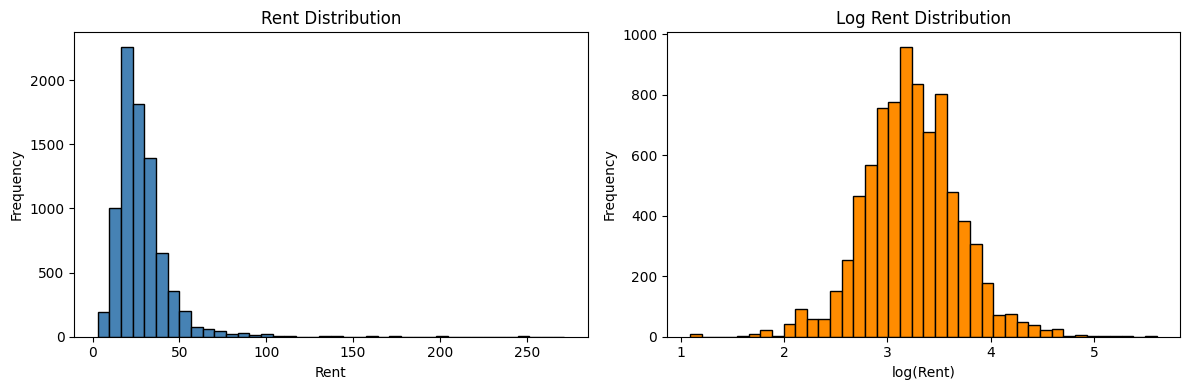

In [789]:
# Compare raw rent and logged rent distributions
fig, axes = subplots(1, 2, figsize=(12, 4))
axes[0].hist(df['Rent'], bins=40, color='steelblue', edgecolor='black')
axes[0].set_title('Rent Distribution')
axes[0].set_xlabel('Rent')
axes[0].set_ylabel('Frequency')

axes[1].hist(df['log_rent'], bins=40, color='darkorange', edgecolor='black')
axes[1].set_title('Log Rent Distribution')
axes[1].set_xlabel('log(Rent)')
axes[1].set_ylabel('Frequency')

fig.tight_layout()

## Create needed variables

In [790]:
# make size in thousands of square feet
# convert leasing rate to percentage, and empl_gr

df['size_mil'] = df['size'] / 1000000
df['occupancy_rate'] = df['leasing_rate']/100
df['empl_gr_rate'] = df['empl_gr']/100

In [791]:
# Create dummy variables for stories
df['high_rise'] = (df['stories'] > 20).astype(int)
df['mid_rise'] = ((df['stories'] > 10) & (df['stories'] < 21)).astype(int)

# Create age-range dummy variables
df['age_under_10'] = (df['age'] < 10).astype(int)
df['age_10_20'] = ((df['age'] >= 10) & (df['age'] < 20)).astype(int)
df['age_20_30'] = ((df['age'] >= 20) & (df['age'] < 30)).astype(int)
df['age_30_40'] = ((df['age'] >= 30) & (df['age'] < 40)).astype(int)

In [792]:
# Create effective rent, which is rent multiplied by occupancy rate
# Only log effective rent when making a df for that model, otherwise 0s are an issue

df['effective_rent'] = df['Rent'] * df['occupancy_rate']


In [793]:
# Create interactions so that we can examine relationship between premium and energy costs
df['green_electricity'] = (
    df['green_rating']* df['Electricity_Costs']
)

df['green_gas'] = (
    df['green_rating'] * df['Gas_Costs']
)

## Fix cost variable formatting

In [794]:
df[['Electricity_Costs', 'Gas_Costs']] = (
    df[['Electricity_Costs', 'Gas_Costs']].round(4)
)

## Deal with missing values - Drop NaNs?

### Note on Missing Values in Replication

The original Stata code initializes the age and stories dummy variables to zero, then assigns a value of one when the relevant condition is met. When age or stories is missing, all corresponding dummy variables remain zero, effectively placing these observations in the omitted reference categories (age > 40 and low-rise buildings, respectively).

This preserves observations in the regressions but implicitly treats missing values as belonging to the reference categories, which is not necessarily appropriate.

**My approach:** Drop observations with missing values in the variables used for the analysis rather than implicitly assigning them to reference categories. This reduces the sample from 8,183 to 7,820 observations.

**Implication:** My regression results may differ from the published results because of the different estimation sample. Document this as a methodological difference in the replication, and consider a robustness check that reproduces the original Stata treatment of missing values to assess its impact on the estimates.

In [795]:
df.isna().sum()

CS_PropertyID           0
id                      0
idgreen              7489
EPA_ID               7698
size                    0
empl_gr                78
Rent                    0
leasing_rate            0
stories                14
age                   280
renovated               0
class_a                 0
class_b                 0
class_c                 0
LEED                    0
Energystar              0
green_rating            0
net                     0
amenities               0
cd_total_07             0
hd_total07              0
total_dd_07             0
Precipitation           0
Gas_Costs               0
Electricity_Costs       0
SEP_Rating           7729
SEP_current          7744
Electricity          7729
Natural_Gas          7729
Other_Energy         7729
Site_EUI             7729
Source_EUI           7729
Emissions            7729
log_rent                0
size_mil                0
occupancy_rate          0
empl_gr_rate           78
high_rise               0
mid_rise    

In [796]:
df_dropna = df.dropna(subset=['empl_gr_rate', 'stories', 'age'])

In [797]:
# Confirm no nulls other than those expected

df_dropna.isnull().sum()

CS_PropertyID           0
id                      0
idgreen              7141
EPA_ID               7344
size                    0
empl_gr                 0
Rent                    0
leasing_rate            0
stories                 0
age                     0
renovated               0
class_a                 0
class_b                 0
class_c                 0
LEED                    0
Energystar              0
green_rating            0
net                     0
amenities               0
cd_total_07             0
hd_total07              0
total_dd_07             0
Precipitation           0
Gas_Costs               0
Electricity_Costs       0
SEP_Rating           7374
SEP_current          7387
Electricity          7374
Natural_Gas          7374
Other_Energy         7374
Site_EUI             7374
Source_EUI           7374
Emissions            7374
log_rent                0
size_mil                0
occupancy_rate          0
empl_gr_rate            0
high_rise               0
mid_rise    

In [798]:
# Drop clusters that become single-building after dropping NaN values

df_dropna = df_dropna[~df_dropna['id'].isin([270, 142, 1147, 289])]

In [917]:
df_dropna['hd_total07'].value_counts()

hd_total07
1419    1568
2739    1101
6001     609
3904     601
6040     492
4783     425
1670     359
1402     258
4796     256
7171     241
2080     179
7200     161
4645     156
2382     137
2472     122
956      114
5979     101
0         94
1923      73
4743      72
5042      68
58        63
1113      46
1891      44
6003      43
376       43
5841      38
4347      38
6496      37
4502      29
5599      28
4916      28
2891      26
3155      24
1178      20
3804      19
1148      18
5493      16
3690      16
403       15
5584       9
1452       9
6068       8
6119       3
6645       3
3972       2
1543       2
6926       2
Name: count, dtype: int64

## Determine what features should be in models

In [799]:
seed = 42

In [890]:
not_to_include = [
    'CS_PropertyID',
    'idgreen',
    'EPA_ID',
    'LEED', 
    'Energystar'
    'class_c', # Omitted category for class
    'SEP_Rating',
    'SEP_current',
    'Electricity',
    'Natural_Gas',
    'Other_Energy',
    'Site_EUI ',
    'Source_EUI',
    'Emissions ',
    'Rent'
]


green = ['green_rating']

cols_all = ['log_rent', 'green_rating', 'size_mil', 'age_under_10', 'age_10_20', 
        'age_20_30', 'age_30_40', 'mid_rise', 'high_rise', 'renovated',
        'class_a', 'class_b', 'net', 'amenities', 'occupancy_rate', 'empl_gr_rate',
        'cd_total_07', 'hd_total07', 'Precipitation', 'Gas_Costs', 'Electricity_Costs',
        'green_electricity', 'green_gas']

cols_no_cluster = ['log_rent', 'green_rating', 'size_mil', 'age_under_10', 'age_10_20', 
        'age_20_30', 'age_30_40', 'mid_rise', 'high_rise', 'renovated',
        'class_a', 'class_b', 'net', 'amenities', 'occupancy_rate', 
        'green_electricity', 'green_gas']

cols_base = ['log_rent', 'size_mil', 'age_under_10', 'age_10_20', 
        'age_20_30', 'age_30_40', 'mid_rise', 'high_rise', 'renovated',
        'class_a', 'class_b', 'net', 'amenities', 'occupancy_rate']

cols_ols = ['log_rent', 'green_rating', 'size_mil', 'age_under_10', 'age_10_20', 
        'age_20_30', 'age_30_40', 'mid_rise', 'high_rise', 'renovated',
        'class_a', 'class_b', 'net', 'amenities', 'occupancy_rate', 'empl_gr_rate']

cols = cols_no_cluster

In [801]:
# Include the Nan rows? Or use df_dropna? DROP NANS

df_model = df_dropna[cols + ['id']].copy()


## Summary Statistics

In [802]:
df_stat = df_dropna.copy()

In [803]:
df_stat.columns

Index(['CS_PropertyID', 'id', 'idgreen', 'EPA_ID', 'size', 'empl_gr', 'Rent',
       'leasing_rate', 'stories', 'age', 'renovated', 'class_a', 'class_b',
       'class_c', 'LEED', 'Energystar', 'green_rating', 'net', 'amenities',
       'cd_total_07', 'hd_total07', 'total_dd_07', 'Precipitation',
       'Gas_Costs', 'Electricity_Costs', 'SEP_Rating', 'SEP_current',
       'Electricity', 'Natural_Gas', 'Other_Energy', 'Site_EUI ', 'Source_EUI',
       'Emissions ', 'log_rent', 'size_mil', 'occupancy_rate', 'empl_gr_rate',
       'high_rise', 'mid_rise', 'age_under_10', 'age_10_20', 'age_20_30',
       'age_30_40', 'effective_rent', 'green_electricity', 'green_gas'],
      dtype='object')

In [804]:
import pandas as pd
import numpy as np

# Change df_model to your analysis DataFrame if necessary.
df_stat = df_dropna.copy()

# Outcome + regression variables
summary_labels = {
    "log_rent": "Log rent per sq. ft.",
    "green_rating": "Green certification",
    "size_mil": "Building size (millions of sq. ft.)",
    "occupancy_rate": "Fraction occupied",
    "class_a": "Class A",
    "class_b": "Class B",
    "net": "Net contract",
    "empl_gr_rate": "Employment growth",
    "age": "Building age (years)",
    "stories": "Number of stories",
    "renovated": "Renovated",
    "amenities": "Amenities",
}

# Include raw age and stories only if they exist.
summary_vars = [v for v in summary_labels if v in df_stat.columns]

summary_table = pd.DataFrame({
    "Variable": [summary_labels[v] for v in summary_vars],
    "N": [df_stat[v].count() for v in summary_vars],
    "Mean": [df_stat[v].mean() for v in summary_vars],
    "SD": [df_stat[v].std() for v in summary_vars],
    "Min": [df_stat[v].min() for v in summary_vars],
    "Median": [df_stat[v].median() for v in summary_vars],
    "Max": [df_stat[v].max() for v in summary_vars],
})

display(summary_table.round(3))

,Variable,N,Mean,SD,Min,Median,Max
0,Log rent per sq. ft.,7816,3.241,0.453,1.092,3.227,5.521
1,Green certification,7816,0.087,0.281,0.000,0.000,1.000
2,Building size (millions of sq. ft.),7816,0.235,0.298,0.002,0.129,3.781
3,Fraction occupied,7816,0.826,0.214,0.000,0.895,1.000
4,Class A,7816,0.399,0.490,0.000,0.000,1.000
5,Class B,7816,0.459,0.498,0.000,0.000,1.000
6,Net contract,7816,0.035,0.184,0.000,0.000,1.000
7,Employment growth,7816,0.032,0.082,-0.250,0.020,0.678
8,Building age (years),7816,47.112,32.035,0.000,34.000,171.000
9,Number of stories,7816,13.596,12.316,1.000,10.000,110.000


In [805]:
# Generate LaTeX table
latex_table = summary_table.round(3).to_latex(
    index=False,
    escape=True,
    column_format="lrrrrrr",
    caption="Summary Statistics",
    label="tab:summary_stats",
    na_rep="--",
)
with open("summary_stats.tex", "w") as f:
    f.write(latex_table)

print(latex_table)

\begin{table}
\caption{Summary Statistics}
\label{tab:summary_stats}
\begin{tabular}{lrrrrrr}
\toprule
Variable & N & Mean & SD & Min & Median & Max \\
\midrule
Log rent per sq. ft. & 7816 & 3.241000 & 0.453000 & 1.092000 & 3.227000 & 5.521000 \\
Green certification & 7816 & 0.087000 & 0.281000 & 0.000000 & 0.000000 & 1.000000 \\
Building size (millions of sq. ft.) & 7816 & 0.235000 & 0.298000 & 0.002000 & 0.129000 & 3.781000 \\
Fraction occupied & 7816 & 0.826000 & 0.214000 & 0.000000 & 0.895000 & 1.000000 \\
Class A & 7816 & 0.399000 & 0.490000 & 0.000000 & 0.000000 & 1.000000 \\
Class B & 7816 & 0.459000 & 0.498000 & 0.000000 & 0.000000 & 1.000000 \\
Net contract & 7816 & 0.035000 & 0.184000 & 0.000000 & 0.000000 & 1.000000 \\
Employment growth & 7816 & 0.032000 & 0.082000 & -0.250000 & 0.020000 & 0.678000 \\
Building age (years) & 7816 & 47.112000 & 32.035000 & 0.000000 & 34.000000 & 171.000000 \\
Number of stories & 7816 & 13.596000 & 12.316000 & 1.000000 & 10.000000 & 110.000000 

In [806]:
# Variables to compare, excluding the treatment indicator itself
compare_vars = [
    v for v in summary_vars
    if v != "green_rating"
]

rows = []

for var in compare_vars:
    non_green_var = df_stat.loc[df_stat["green_rating"] == 0, var].dropna()
    green_var = df_stat.loc[df_stat["green_rating"] == 1, var].dropna()

    rows.append({
        "Variable": summary_labels[var],
        "Non-green N": len(non_green_var),
        "Non-green mean (SD)": (
            f"{non_green_var.mean():.3f} ({non_green_var.std():.3f})"
        ),
        "Green N": len(green_var),
        "Green mean (SD)": (
            f"{green_var.mean():.3f} ({green_var.std():.3f})"
        ),
        "Difference (green - non-green)": (
            green_var.mean() - non_green_var.mean()
            if len(green_var) > 0 and len(non_green_var) > 0
            else np.nan
        ),
    })

green_comparison = pd.DataFrame(rows)

display(green_comparison.round(3))

,Variable,Non-green N,Non-green mean (SD),Green N,Green mean (SD),Difference (green - non-green)
0,Log rent per sq. ft.,7139,3.233 (0.459),677,3.325 (0.384),0.091
1,Building size (millions of sq. ft.),7139,0.226 (0.297),677,0.327 (0.291),0.100
2,Fraction occupied,7139,0.820 (0.219),677,0.893 (0.123),0.073
3,Class A,7139,0.361 (0.480),677,0.796 (0.403),0.435
4,Class B,7139,0.485 (0.500),677,0.194 (0.395),-0.291
5,Net contract,7139,0.033 (0.178),677,0.058 (0.233),0.025
6,Employment growth,7139,0.032 (0.080),677,0.035 (0.096),0.003
7,Building age (years),7139,49.307 (32.325),677,23.965 (15.594),-25.343
8,Number of stories,7139,13.427 (12.204),677,15.380 (13.321),1.953
9,Renovated,7139,0.395 (0.489),677,0.214 (0.411),-0.180


In [807]:
# Generate LaTeX table
latex_table = green_comparison.round(3).to_latex(
    index=False,
    escape=True,
    column_format="lrrrrrr",
    caption="Green Comparison",
    label="tab:green_comparison",
    na_rep="--",
)
with open("green_comp.tex", "w") as f:
    f.write(latex_table)

print(latex_table)

\begin{table}
\caption{Green Comparison}
\label{tab:green_comparison}
\begin{tabular}{lrrrrrr}
\toprule
Variable & Non-green N & Non-green mean (SD) & Green N & Green mean (SD) & Difference (green - non-green) \\
\midrule
Log rent per sq. ft. & 7139 & 3.233 (0.459) & 677 & 3.325 (0.384) & 0.091000 \\
Building size (millions of sq. ft.) & 7139 & 0.226 (0.297) & 677 & 0.327 (0.291) & 0.100000 \\
Fraction occupied & 7139 & 0.820 (0.219) & 677 & 0.893 (0.123) & 0.073000 \\
Class A & 7139 & 0.361 (0.480) & 677 & 0.796 (0.403) & 0.435000 \\
Class B & 7139 & 0.485 (0.500) & 677 & 0.194 (0.395) & -0.291000 \\
Net contract & 7139 & 0.033 (0.178) & 677 & 0.058 (0.233) & 0.025000 \\
Employment growth & 7139 & 0.032 (0.080) & 677 & 0.035 (0.096) & 0.003000 \\
Building age (years) & 7139 & 49.307 (32.325) & 677 & 23.965 (15.594) & -25.343000 \\
Number of stories & 7139 & 13.427 (12.204) & 677 & 15.380 (13.321) & 1.953000 \\
Renovated & 7139 & 0.395 (0.489) & 677 & 0.214 (0.411) & -0.180000 \\
Ameni

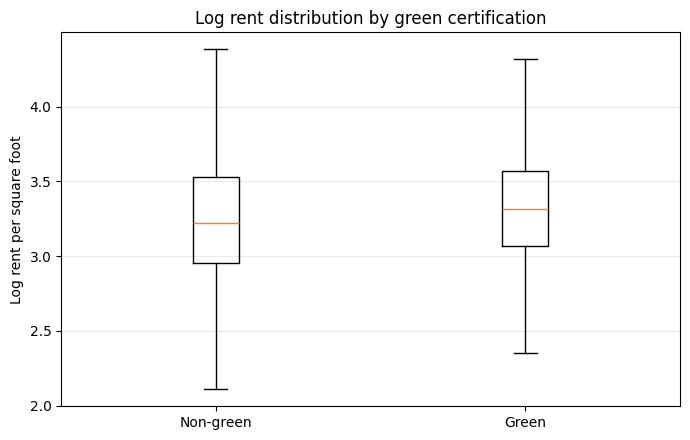

In [808]:
import matplotlib.pyplot as plt

rent_data = [
    df_stat.loc[df_stat["green_rating"] == 0, "log_rent"].dropna(),
    df_stat.loc[df_stat["green_rating"] == 1, "log_rent"].dropna(),
]

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.boxplot(
    rent_data,
    tick_labels=["Non-green", "Green"],
    showfliers=False
)

ax.set_ylabel("Log rent per square foot")
ax.set_title("Log rent distribution by green certification")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

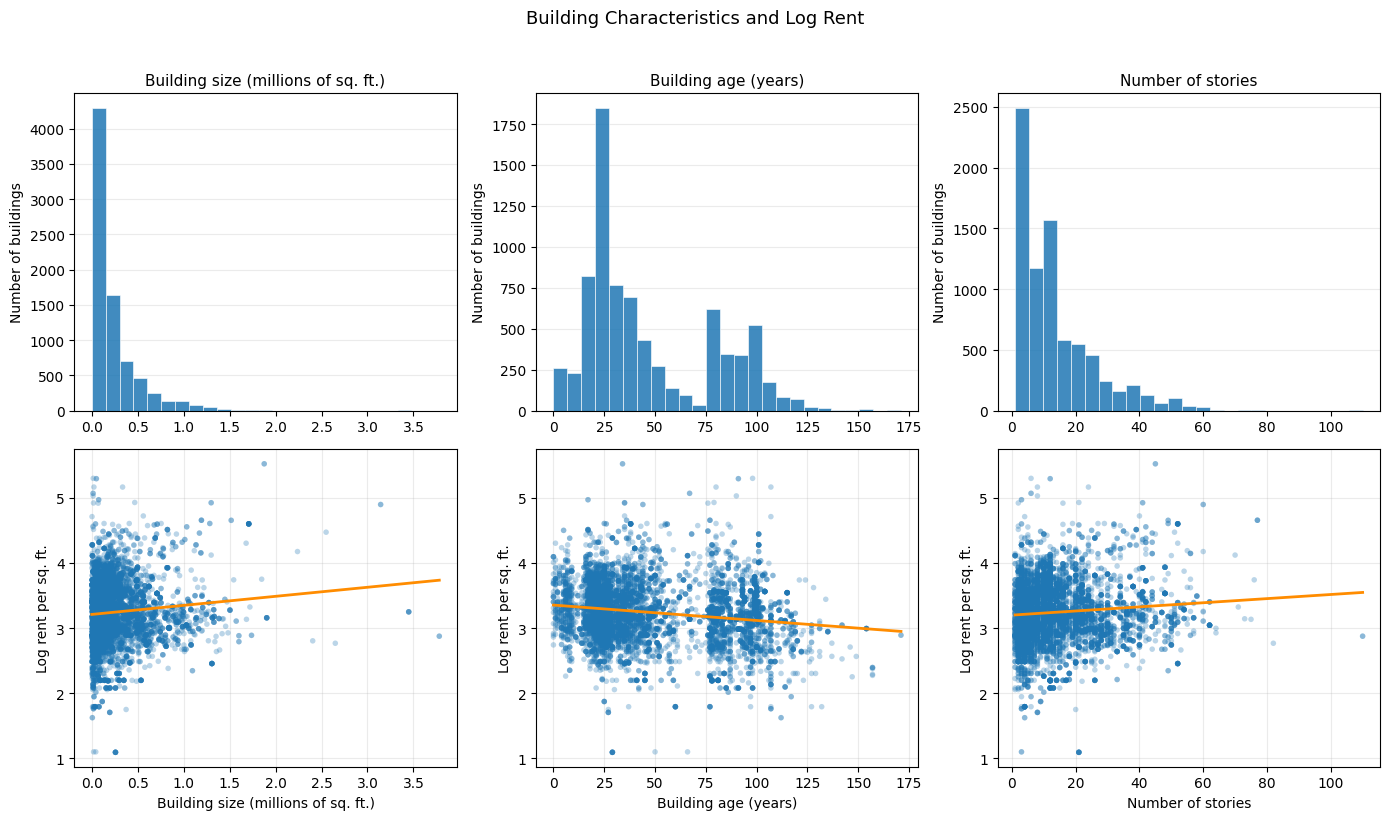

In [809]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

characteristics = [
    ("size_mil", "Building size (millions of sq. ft.)"),
    ("age", "Building age (years)"),
    ("stories", "Number of stories"),
]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for j, (var, label) in enumerate(characteristics):
    # Top row: histogram
    ax_hist = axes[0, j]
    values = df_dropna[var].dropna()

    ax_hist.hist(
        values,
        bins=25,
        edgecolor="white",
        linewidth=0.5,
        alpha=0.85,
    )

    ax_hist.set_title(label, fontsize=11)
    ax_hist.set_ylabel("Number of buildings")
    ax_hist.grid(axis="y", alpha=0.25)
    ax_hist.set_axisbelow(True)

    # Bottom row: scatterplot against log rent
    ax_scatter = axes[1, j]
    plot_data = df_dropna[[var, "log_rent"]].dropna()

    x = plot_data[var].to_numpy()
    y = plot_data["log_rent"].to_numpy()

    ax_scatter.scatter(
        x, y,
        alpha=0.3,
        s=16,
        edgecolors="none",
    )

    # Add linear trend line
    if len(plot_data) >= 2 and np.unique(x).size >= 2:
        slope, intercept = np.polyfit(x, y, 1)
        x_line = np.linspace(x.min(), x.max(), 100)
        ax_scatter.plot(
            x_line,
            intercept + slope * x_line,
            color="darkorange",
            linewidth=2,
        )

    ax_scatter.set_xlabel(label)
    ax_scatter.set_ylabel("Log rent per sq. ft.")
    ax_scatter.grid(alpha=0.25)
    ax_scatter.set_axisbelow(True)

fig.suptitle(
    "Building Characteristics and Log Rent",
    fontsize=13,
    y=1.02,
)

plt.tight_layout()
plt.show()

### Binned cluster visual?

In [810]:
import numpy as np
import pandas as pd

df_cluster_graph = df_dropna.copy()                       # one row per building

# ---- names: change these if yours differ ----
cluster = 'id'
elec, gas = 'Electricity_Costs', 'Gas_Costs'
controls = ['size_mil', 'occupancy_rate', 'class_a', 'class_b', 'net',
            'age_under_10', 'age_10_20', 'age_20_30', 'age_30_40',
            'renovated', 'mid_rise', 'high_rise', 'amenities']

# energy costs should take a single value within each cluster
assert (df_cluster_graph.groupby(cluster)[[elec, gas]].nunique() <= 1).all().all(), 'costs vary within a cluster'

# 1. Raw gap: certified building minus the average uncertified building in its cluster
green_mean = df_cluster_graph[df_cluster_graph['green_rating'] == 1].groupby(cluster)['log_rent'].mean()
nongreen_mean = df_cluster_graph[df_cluster_graph['green_rating'] == 0].groupby(cluster)['log_rent'].mean()
gap_raw = (green_mean - nongreen_mean).rename('gap_raw')

# 2. Adjusted gap: remove the effect of building characteristics first.
#    The characteristics' coefficients come from the within-cluster regression
#    (every variable minus its cluster mean), the same as cluster fixed effects.
cols_graph = ['log_rent', 'green_rating'] + controls
dm = df_cluster_graph[cols_graph] - df_cluster_graph.groupby(cluster)[cols_graph].transform('mean')
beta, *_ = np.linalg.lstsq(dm[['green_rating'] + controls].to_numpy(),
                           dm['log_rent'].to_numpy(), rcond=None)
beta_controls = pd.Series(beta[1:], index=controls)
df_cluster_graph['log_rent_adj'] = df_cluster_graph['log_rent'] - df_cluster_graph[controls] @ beta_controls

green_mean_adj = df_cluster_graph[df_cluster_graph['green_rating'] == 1].groupby(cluster)['log_rent_adj'].mean()
nongreen_mean_adj = df_cluster_graph[df_cluster_graph['green_rating'] == 0].groupby(cluster)['log_rent_adj'].mean()
gap_adj = (green_mean_adj - nongreen_mean_adj).rename('gap_adj')

# 3. One row per cluster: the gaps plus the cluster's energy costs
costs = df_cluster_graph.groupby(cluster)[[elec, gas]].first()
cluster_gap = pd.concat([gap_raw, gap_adj, costs], axis=1, join='inner').dropna()

print(f'{len(cluster_gap)} clusters with both a certified and an uncertified building')
print(cluster_gap.describe().round(3))

677 clusters with both a certified and an uncertified building
       gap_raw  gap_adj  Electricity_Costs  Gas_Costs
count  677.000  677.000            677.000    677.000
mean     0.120    0.030              0.032      0.011
std      0.226    0.213              0.008      0.002
min     -0.718   -0.792              0.018      0.010
25%      0.000   -0.074              0.024      0.010
50%      0.123    0.044              0.034      0.010
75%      0.245    0.153              0.038      0.012
max      1.208    1.048              0.063      0.029


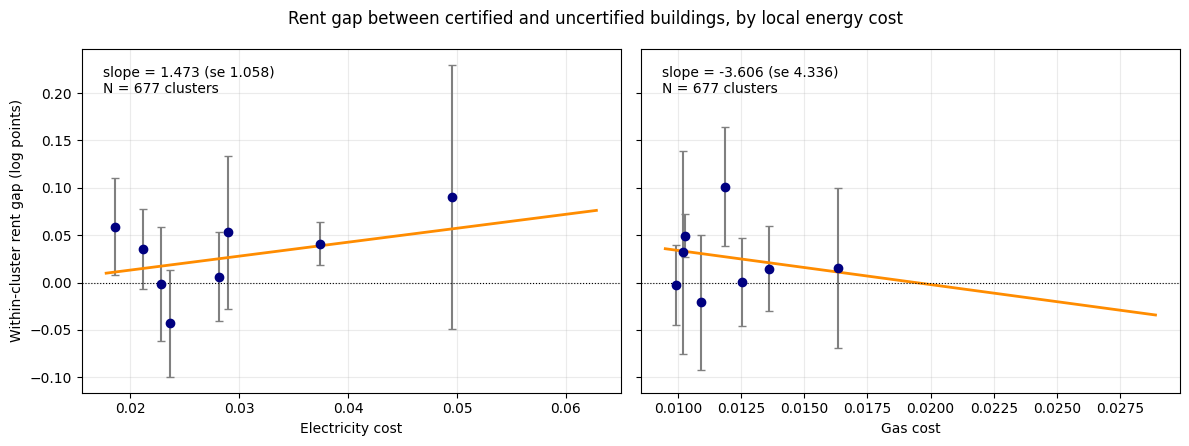

In [811]:
import matplotlib.pyplot as plt
from scipy.stats import linregress

def binned_scatter(ax, data, xcol, ycol, xlabel, nbins=15):
    d = data[[xcol, ycol]].dropna().copy()

    # group clusters into bins of equal size by energy cost
    d['bin'] = pd.qcut(d[xcol], q=nbins, duplicates='drop')
    b = d.groupby('bin', observed=True).agg(
        x=(xcol, 'mean'),
        y=(ycol, 'mean'),
        se=(ycol, lambda s: s.std(ddof=1) / np.sqrt(len(s))),
    )
    ax.errorbar(b['x'], b['y'], yerr=1.96 * b['se'], fmt='o', color='navy',
                ecolor='gray', capsize=3)

    # the line is fit to the cluster-level data, not to the bin means
    fit = linregress(d[xcol], d[ycol])
    xs = np.linspace(d[xcol].min(), d[xcol].max(), 100)
    ax.plot(xs, fit.intercept + fit.slope * xs, color='darkorange', lw=2)

    ax.axhline(0, color='black', lw=0.8, ls=':')
    ax.set_xlabel(xlabel)
    ax.text(0.04, 0.95, f'slope = {fit.slope:.3f} (se {fit.stderr:.3f})\nN = {len(d)} clusters',
            transform=ax.transAxes, va='top', fontsize=10)
    ax.grid(alpha=0.25)

ycol = 'gap_adj'          # use 'gap_raw' for the version without controls

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
binned_scatter(axes[0], cluster_gap, elec, ycol, 'Electricity cost')
binned_scatter(axes[1], cluster_gap, gas, ycol, 'Gas cost')
axes[0].set_ylabel('Within-cluster rent gap (log points)')
fig.suptitle('Rent gap between certified and uncertified buildings, by local energy cost')
fig.tight_layout()
fig.savefig('img/premium_vs_energy_cost.png', dpi=200, bbox_inches='tight')
plt.show()

## Adding Cluster FEs - De-meaning

- de-mean prior to train-test split, or de-mean within each split?
- Prof suggested within, we can check if data leakage is an issue later
- ALSO: make sure the de-meaned equation model is reported in paper

### De-mean pre-split
- Post-split is the correct approach I think

In [812]:
""" # De-mean variables other than green_rating - PRE-SPLIT

df_model_demeaned = df_model.copy()




cluster_means = df_model.groupby('id')[cols].transform('mean')

df_model_demeaned[cols] = df_model[cols] - cluster_means """;

In [813]:
""" # PRE-SPLIT METHOD

X = df_model_demeaned[cols].drop(columns=['log_rent'])
d = df_model_demeaned[green]
y = df_model_demeaned['log_rent'] """;

### De-Mean post-split

In [814]:
# Option to get around the clusters for splitting into train and test
# Doing this for assignment, but check if it will ultimately be needed
feat = [c for c in cols if c not in ('Rent', 'log_rent')]

# 1. Row-level split, then make sure every test cluster also has training rows
test = df_model.sample(frac=0.25, random_state=seed)
train = df_model.drop(test.index)
orphan = ~test['id'].isin(train['id'])  
train = pd.concat([train, test[orphan]])    
test = test[~orphan]

# 2. Cluster means from train only
train_means = train.groupby('id')[feat + ['log_rent']].mean()

def demean_and_keep(d):
    m = train_means.reindex(d['id'])
    m.index = d.index
    
    # Create a copy of the dataframe segment
    d_processed = d.copy()
    
    # Overwrite only the ols columns with their de-meaned versions
    d_processed[feat] = d[feat] - m[feat]
    d_processed['log_rent'] = d['log_rent'] - m['log_rent']
    
    return d_processed

train_demeaned = demean_and_keep(train)
test_demeaned = demean_and_keep(test)

In [815]:
# Train test split on already De-Meaned data

X_train = train_demeaned[cols].drop(columns=['log_rent'])
X_test = test_demeaned[cols].drop(columns=['log_rent'])

y_train = train_demeaned['log_rent']
y_test = test_demeaned['log_rent']

# OLS

- Note: rank condition warnings are just due to some variables being constant across cluster - safe to ignore


## Base OLS models

In [816]:
df_ols = df_dropna[cols_ols + ['id']].copy()

y_ols = df_ols['log_rent']
X_ols = df_ols.drop(columns=['log_rent', 'id'])

# Add dummy variables for cluster id
id_dummies = pd.get_dummies(
    df_ols["id"],
    prefix="id",
    drop_first=True,
    dtype=int
)

X_ols = pd.concat([X_ols, id_dummies], axis=1)

In [817]:
# Basic OLS model
X_ols_const = sm.add_constant(X_ols)
model = sm.OLS(y_ols, X_ols_const)
results = model.fit(cov_type='cluster', cov_kwds={'groups': df_ols['id']}, use_t=True)

In [818]:
# Define nested specifications
specs = [
    [
        "green_rating", "size_mil", "occupancy_rate",
        "class_a", "class_b", "net", "empl_gr_rate"
    ],
    [
        "green_rating", "size_mil", "occupancy_rate",
        "class_a", "class_b", "net", "empl_gr_rate",
        "age_under_10", "age_10_20", "age_20_30", "age_30_40"
    ],
    [
        "green_rating", "size_mil", "occupancy_rate",
        "class_a", "class_b", "net", "empl_gr_rate",
        "age_under_10", "age_10_20", "age_20_30", "age_30_40",
        "renovated", "mid_rise", "high_rise"
    ],
    [
        "green_rating", "size_mil", "occupancy_rate",
        "class_a", "class_b", "net", "empl_gr_rate",
        "age_under_10", "age_10_20", "age_20_30", "age_30_40",
        "renovated", "mid_rise", "high_rise", "amenities"
    ]
]

models = []

for variables in specs:
    X = pd.concat(
        [X_ols[variables], id_dummies],
        axis=1
    )
    X = sm.add_constant(X)

    model = sm.OLS(y_ols, X).fit(
        cov_type="cluster",
        cov_kwds={"groups": df_ols["id"]},
        use_t=True
    )

    models.append(model)

In [819]:
# Display regression results without cluster fixed-effect dummies

for i, results in enumerate(models, start=1):
    print(f"\nModel ({i})")
    print("-" * 60)

    # Exclude the intercept and cluster fixed effects from display
    displayed_vars = [
        var for var in results.params.index
        if var != "const" and not var.startswith("id_")
    ]

    summary = pd.DataFrame({
        "Coefficient": results.params[displayed_vars],
        "Std. Error": results.bse[displayed_vars],
        "t-stat": results.tvalues[displayed_vars],
        "P-value": results.pvalues[displayed_vars]
    })

    print(summary.round(4).to_string())

    print(f"\nObservations: {int(results.nobs)}")
    print(f"R-squared:    {results.rsquared:.4f}")
    print(f"Adj. R-squared: {results.rsquared_adj:.4f}")
    print("Cluster fixed effects: Yes")


Model (1)
------------------------------------------------------------
                Coefficient  Std. Error   t-stat  P-value
green_rating         0.0364      0.0091   3.9902   0.0001
size_mil             0.1150      0.0248   4.6328   0.0000
occupancy_rate       0.0255      0.0179   1.4270   0.1540
class_a              0.2304      0.0128  17.9390   0.0000
class_b              0.0972      0.0121   8.0037   0.0000
net                 -0.0356      0.0170  -2.0971   0.0364
empl_gr_rate        -0.2374      0.0036 -66.2666   0.0000

Observations: 7816
R-squared:    0.7232
Adj. R-squared: 0.6965
Cluster fixed effects: Yes

Model (2)
------------------------------------------------------------
                Coefficient  Std. Error   t-stat  P-value
green_rating         0.0343      0.0090   3.8059   0.0002
size_mil             0.1047      0.0243   4.3133   0.0000
occupancy_rate       0.0253      0.0177   1.4288   0.1535
class_a              0.1908      0.0139  13.7633   0.0000
class_b    

In [820]:
# THE ONE I'M ACTUALLY USING

stargazer = Stargazer(models)

# Column headings and title
stargazer.custom_columns(
    ["(1)", "(2)", "(3)", "(4)"],
    [1, 1, 1, 1]
)
stargazer.title("Commercial Office Rents and Green Ratings")
stargazer.dependent_variable_name("Log rent per square foot")

# Variable labels
variable_labels = {
    "green_rating": "Green rating",
    "size_mil": "Building size (millions of sq. ft.)",
    "occupancy_rate": "Fraction occupied",
    "class_a": "Class A",
    "class_b": "Class B",
    "net": "Net contract",
    "empl_gr_rate": "Employment growth",
    "age_under_10": "< 10 years",
    "age_10_20": "10--20 years",
    "age_20_30": "20--30 years",
    "age_30_40": "30--40 years",
    "renovated": "Renovated",
    "mid_rise": "Intermediate stories",
    "high_rise": "High stories",
    "amenities": "Amenities",
}

stargazer.rename_covariates(variable_labels)

# Presentation
stargazer.significant_digits(3)

stargazer.show_r2 = True
stargazer.show_adj_r2 = False
stargazer.show_n = True
stargazer.show_f_statistic = False
stargazer.show_residual_std_err = False
stargazer.show_degrees_of_freedom = False
stargazer.show_confidence_intervals = False

# Suppress the hundreds of cluster dummy coefficients
stargazer.covariate_order(list(variable_labels.keys()))
stargazer.add_line("Matched-cluster fixed effects", ["Yes"] * 4)
stargazer.add_line("Clustered standard errors", ["Yes"] * 4)

# Export LaTeX
latex = stargazer.render_latex()

with open("green_rent_ols.tex", "w") as f:
    f.write(latex)

print(latex)

/opt/anaconda3/envs/pydata/lib/python3.11/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 689, but rank is 6
  warnings.warn('covariance of constraints does not have full '
/opt/anaconda3/envs/pydata/lib/python3.11/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 693, but rank is 10
  warnings.warn('covariance of constraints does not have full '
/opt/anaconda3/envs/pydata/lib/python3.11/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 696, but rank is 13
  warnings.warn('covariance of constraints does not have full '


\begin{table}[!htbp] \centering
  \caption{Commercial Office Rents and Green Ratings}
\begin{tabular}{@{\extracolsep{5pt}}lcccc}
\\[-1.8ex]\hline
\hline \\[-1.8ex]
& \multicolumn{4}{c}{\textit{Dependent variable: Log rent per square foot}} \
\cr \cline{2-5}
\\[-1.8ex] & \multicolumn{1}{c}{(1)} & \multicolumn{1}{c}{(2)} & \multicolumn{1}{c}{(3)} & \multicolumn{1}{c}{(4)}  \\
\\[-1.8ex] & (1) & (2) & (3) & (4) \\
\hline \\[-1.8ex]
 Green rating & 0.036$^{***}$ & 0.034$^{***}$ & 0.032$^{***}$ & 0.030$^{***}$ \\
& (0.009) & (0.009) & (0.009) & (0.009) \\
 Building size (millions of sq. ft.) & 0.115$^{***}$ & 0.105$^{***}$ & 0.114$^{***}$ & 0.106$^{***}$ \\
& (0.025) & (0.024) & (0.029) & (0.028) \\
 Fraction occupied & 0.025$^{}$ & 0.025$^{}$ & 0.019$^{}$ & 0.012$^{}$ \\
& (0.018) & (0.018) & (0.018) & (0.018) \\
 Class A & 0.230$^{***}$ & 0.191$^{***}$ & 0.183$^{***}$ & 0.166$^{***}$ \\
& (0.013) & (0.014) & (0.015) & (0.015) \\
 Class B & 0.097$^{***}$ & 0.087$^{***}$ & 0.082$^{***}$ & 0

/opt/anaconda3/envs/pydata/lib/python3.11/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 697, but rank is 14
  warnings.warn('covariance of constraints does not have full '


## OLS without occupancy rate

In [904]:
# Define nested specifications
specs = [
    [
        "green_rating", "size_mil", "occupancy_rate",
        "class_a", "class_b", "net", "empl_gr_rate"
    ],
    [
        "green_rating", "size_mil", "occupancy_rate",
        "class_a", "class_b", "net", "empl_gr_rate",
        "age_under_10", "age_10_20", "age_20_30", "age_30_40"
    ],
    [
        "green_rating", "size_mil", "occupancy_rate",
        "class_a", "class_b", "net", "empl_gr_rate",
        "age_under_10", "age_10_20", "age_20_30", "age_30_40",
        "renovated", "mid_rise", "high_rise"
    ],
    [
        "green_rating", "size_mil", "occupancy_rate",
        "class_a", "class_b", "net", "empl_gr_rate",
        "age_under_10", "age_10_20", "age_20_30", "age_30_40",
        "renovated", "mid_rise", "high_rise", "amenities"
    ]
]

# Estimate models with and without occupancy rate
models_with_occ = []
models_without_occ = []

for variables in specs:

    # Original specification
    X_with = pd.concat(
        [X_ols[variables], id_dummies],
        axis=1
    )
    X_with = sm.add_constant(X_with)

    model_with = sm.OLS(y_ols, X_with).fit(
        cov_type="cluster",
        cov_kwds={"groups": df_ols["id"]},
        use_t=True
    )
    models_with_occ.append(model_with)

    # Alternative specification: remove occupancy rate
    variables_no_occ = [
        var for var in variables if var != "occupancy_rate"
    ]

    X_without = pd.concat(
        [X_ols[variables_no_occ], id_dummies],
        axis=1
    )
    X_without = sm.add_constant(X_without)

    model_without = sm.OLS(y_ols, X_without).fit(
        cov_type="cluster",
        cov_kwds={"groups": df_ols["id"]},
        use_t=True
    )
    models_without_occ.append(model_without)

In [905]:
comparison = []

for i, (m_with, m_without) in enumerate(
    zip(models_with_occ, models_without_occ), start=1
):
    comparison.append({
        "Model": f"({i})",
        "Green coef. (with occupancy)": m_with.params["green_rating"],
        "SE (with occupancy)": m_with.bse["green_rating"],
        "p-value (with occupancy)": m_with.pvalues["green_rating"],
        "Green coef. (without occupancy)": m_without.params["green_rating"],
        "SE (without occupancy)": m_without.bse["green_rating"],
        "p-value (without occupancy)": m_without.pvalues["green_rating"],
    })

comparison_df = pd.DataFrame(comparison).set_index("Model")
print(comparison_df.round(4).to_string())

       Green coef. (with occupancy)  SE (with occupancy)  p-value (with occupancy)  Green coef. (without occupancy)  SE (without occupancy)  p-value (without occupancy)
Model                                                                                                                                                                   
(1)                          0.0364               0.0091                    0.0001                           0.0375                  0.0091                       0.0000
(2)                          0.0343               0.0090                    0.0002                           0.0353                  0.0090                       0.0001
(3)                          0.0324               0.0089                    0.0003                           0.0332                  0.0089                       0.0002
(4)                          0.0296               0.0090                    0.0010                           0.0300                  0.0089                

## OLS with energy interactions

In [896]:
df_ols_energy = df_dropna[cols_no_cluster + ['id']].copy()

y_ols_energy = df_ols_energy['log_rent']
X_ols_energy = df_ols_energy.drop(columns=['log_rent', 'id'])

# Add dummy variables for cluster id
id_dummies = pd.get_dummies(
    df_ols_energy["id"],
    prefix="id",
    drop_first=True,
    dtype=int
)

X_ols_energy = pd.concat([X_ols_energy, id_dummies], axis=1)

In [897]:
# Basic OLS model
X_ols_energy_const = sm.add_constant(X_ols_energy)
model_energy = sm.OLS(y_ols_energy, X_ols_energy_const)
results = model_energy.fit(cov_type='cluster', cov_kwds={'groups': df_ols_energy['id']}, use_t=True)

In [900]:
# Define nested specifications
specs_energy = [
    [
        "green_rating", "size_mil", 
        "class_a", "class_b", "net", 
        "age_under_10", "age_10_20", "age_20_30", "age_30_40"
    ],
    [
        "green_rating", "size_mil", "class_a", "class_b", "net", 
        "age_under_10", "age_10_20", "age_20_30", "age_30_40",
        "renovated", "mid_rise", "high_rise", "amenities",
        "green_gas"
    ],
    [
        "green_rating", "size_mil", "class_a", "class_b", "net", 
        "age_under_10", "age_10_20", "age_20_30", "age_30_40",
        "renovated", "mid_rise", "high_rise", "amenities",
        "green_electricity"
    ],
    [
        "green_rating", "size_mil", 
        "class_a", "class_b", "net",
        "age_under_10", "age_10_20", "age_20_30", "age_30_40",
        "renovated", "mid_rise", "high_rise", "amenities",
        "green_gas", "green_electricity"
    ]
]

models_energy = []

for variables in specs_energy:
    X = pd.concat(
        [X_ols_energy[variables], id_dummies],
        axis=1
    )
    X = sm.add_constant(X)

    model = sm.OLS(y_ols_energy, X).fit(
        cov_type="cluster",
        cov_kwds={"groups": df_ols_energy["id"]},
        use_t=True
    )

    models_energy.append(model)

In [901]:
# Display regression results without cluster fixed-effect dummies

for i, results in enumerate(models_energy, start=1):
    print(f"\nModel ({i})")
    print("-" * 60)

    # Exclude the intercept and cluster fixed effects from display
    displayed_vars = [
        var for var in results.params.index
        if var != "const" and not var.startswith("id_")
    ]

    summary = pd.DataFrame({
        "Coefficient": results.params[displayed_vars],
        "Std. Error": results.bse[displayed_vars],
        "t-stat": results.tvalues[displayed_vars],
        "P-value": results.pvalues[displayed_vars]
    })

    print(summary.round(4).to_string())

    print(f"\nObservations: {int(results.nobs)}")
    print(f"R-squared:    {results.rsquared:.4f}")
    print(f"Adj. R-squared: {results.rsquared_adj:.4f}")
    print("Cluster fixed effects: Yes")


Model (1)
------------------------------------------------------------
              Coefficient  Std. Error   t-stat  P-value
green_rating       0.0353      0.0090   3.9256   0.0001
size_mil           0.1072      0.0240   4.4622   0.0000
class_a            0.1939      0.0138  14.0617   0.0000
class_b            0.0889      0.0117   7.5981   0.0000
net               -0.0379      0.0173  -2.1948   0.0285
age_under_10       0.1173      0.0175   6.6934   0.0000
age_10_20          0.0886      0.0148   5.9858   0.0000
age_20_30          0.0531      0.0105   5.0719   0.0000
age_30_40          0.0436      0.0105   4.1302   0.0000

Observations: 7816
R-squared:    0.7258
Adj. R-squared: 0.6992
Cluster fixed effects: Yes

Model (2)
------------------------------------------------------------
              Coefficient  Std. Error   t-stat  P-value
green_rating       0.0600      0.0747   0.8023   0.4226
size_mil           0.1072      0.0283   3.7889   0.0002
class_a            0.1663      0.0155

In [906]:
# THE ONE I'M ACTUALLY USING

stargazer = Stargazer(models_energy)

# Column headings and title
stargazer.custom_columns(
    ["(1)", "(2)", "(3)", "(4)"],
    [1, 1, 1, 1]
)
stargazer.title("Commercial Office Rents and Green Ratings - Energy Interactions")
stargazer.dependent_variable_name("Log rent per square foot")

# Variable labels
variable_labels = {
    "green_rating": "Green rating",
    "size_mil": "Building size (millions of sq. ft.)",
    "class_a": "Class A",
    "class_b": "Class B",
    "net": "Net contract",
    "age_under_10": "< 10 years",
    "age_10_20": "10--20 years",
    "age_20_30": "20--30 years",
    "age_30_40": "30--40 years",
    "renovated": "Renovated",
    "mid_rise": "Intermediate stories",
    "high_rise": "High stories",
    "amenities": "Amenities",
    "green_gas": "Green rating x Gas costs",
    "green_electricity": "Green rating x Electricity costs"
}

stargazer.rename_covariates(variable_labels)

# Presentation
stargazer.significant_digits(3)

stargazer.show_r2 = True
stargazer.show_adj_r2 = False
stargazer.show_n = True
stargazer.show_f_statistic = False
stargazer.show_residual_std_err = False
stargazer.show_degrees_of_freedom = False
stargazer.show_confidence_intervals = False

# Suppress the hundreds of cluster dummy coefficients
stargazer.covariate_order(list(variable_labels.keys()))
stargazer.add_line("Matched-cluster fixed effects", ["Yes"] * 4)
stargazer.add_line("Clustered standard errors", ["Yes"] * 4)

# Export LaTeX
latex = stargazer.render_latex()

with open("green_rent_ols_energy.tex", "w") as f:
    f.write(latex)

print(latex)

/opt/anaconda3/envs/pydata/lib/python3.11/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 691, but rank is 9
  warnings.warn('covariance of constraints does not have full '
/opt/anaconda3/envs/pydata/lib/python3.11/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 696, but rank is 14
  warnings.warn('covariance of constraints does not have full '


\begin{table}[!htbp] \centering
  \caption{Commercial Office Rents and Green Ratings - Energy Interactions}
\begin{tabular}{@{\extracolsep{5pt}}lcccc}
\\[-1.8ex]\hline
\hline \\[-1.8ex]
& \multicolumn{4}{c}{\textit{Dependent variable: Log rent per square foot}} \
\cr \cline{2-5}
\\[-1.8ex] & \multicolumn{1}{c}{(1)} & \multicolumn{1}{c}{(2)} & \multicolumn{1}{c}{(3)} & \multicolumn{1}{c}{(4)}  \\
\\[-1.8ex] & (1) & (2) & (3) & (4) \\
\hline \\[-1.8ex]
 Green rating & 0.035$^{***}$ & 0.060$^{}$ & -0.011$^{}$ & 0.020$^{}$ \\
& (0.009) & (0.075) & (0.039) & (0.096) \\
 Building size (millions of sq. ft.) & 0.107$^{***}$ & 0.107$^{***}$ & 0.108$^{***}$ & 0.108$^{***}$ \\
& (0.024) & (0.028) & (0.028) & (0.028) \\
 Class A & 0.194$^{***}$ & 0.166$^{***}$ & 0.166$^{***}$ & 0.166$^{***}$ \\
& (0.014) & (0.016) & (0.016) & (0.016) \\
 Class B & 0.089$^{***}$ & 0.076$^{***}$ & 0.076$^{***}$ & 0.076$^{***}$ \\
& (0.012) & (0.012) & (0.012) & (0.012) \\
 Net contract & -0.038$^{**}$ & -0.039$^{**}

/opt/anaconda3/envs/pydata/lib/python3.11/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 696, but rank is 14
  warnings.warn('covariance of constraints does not have full '
/opt/anaconda3/envs/pydata/lib/python3.11/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 697, but rank is 15
  warnings.warn('covariance of constraints does not have full '


## Effective rent OLS models

In [821]:
# Create df for running the log_effective_rent model. Will have to drop the rows where occupancy rate is 0, so this needs to be noted in analysis

df_ols_eff_rent = df_dropna[cols_ols + ['id'] + ['effective_rent']].copy()
df_ols_eff_rent = df_ols_eff_rent[df_ols_eff_rent['occupancy_rate'] != 0].copy()

df_ols_eff_rent['log_effective_rent'] = np.log(df_ols_eff_rent['effective_rent'])

In [822]:
y_ols_eff = df_ols_eff_rent['log_effective_rent']
X_ols_eff = df_ols_eff_rent.drop(
    columns=['log_effective_rent', 'effective_rent', 'log_rent', 'id', 'occupancy_rate']
    )

# Add dummy variables for cluster id
id_dummies_eff = pd.get_dummies(
    df_ols_eff_rent["id"],
    prefix="id",
    drop_first=True,
    dtype=int
)

X_ols_eff = pd.concat([X_ols_eff, id_dummies_eff], axis=1)

In [823]:
# Basic OLS model - effective rent
X_ols_eff_const = sm.add_constant(X_ols_eff)
model_eff = sm.OLS(y_ols_eff, X_ols_eff_const)
results_eff = model_eff.fit(cov_type='cluster', cov_kwds={'groups': df_ols_eff_rent['id']}, use_t=True)

In [824]:
# Define nested specifications
specs = [
    [
        "green_rating", "size_mil",
        "class_a", "class_b", "net", "empl_gr_rate"
    ],
    [
        "green_rating", "size_mil", 
        "class_a", "class_b", "net", "empl_gr_rate",
        "age_under_10", "age_10_20", "age_20_30", "age_30_40"
    ],
    [
        "green_rating", "size_mil", 
        "class_a", "class_b", "net", "empl_gr_rate",
        "age_under_10", "age_10_20", "age_20_30", "age_30_40",
        "renovated", "mid_rise", "high_rise"
    ],
    [
        "green_rating", "size_mil", 
        "class_a", "class_b", "net", "empl_gr_rate",
        "age_under_10", "age_10_20", "age_20_30", "age_30_40",
        "renovated", "mid_rise", "high_rise", "amenities"
    ]
]

models_eff = []

for variables in specs:
    X = pd.concat(
        [X_ols_eff[variables], id_dummies_eff],
        axis=1
    )
    X = sm.add_constant(X)

    model = sm.OLS(y_ols_eff, X).fit(
        cov_type="cluster",
        cov_kwds={"groups": df_ols_eff_rent["id"]},
        use_t=True
    )

    models_eff.append(model)

In [825]:
# Display regression results without cluster fixed-effect dummies

for i, results in enumerate(models_eff, start=1):
    print(f"\nModel ({i})")
    print("-" * 60)

    # Exclude the intercept and cluster fixed effects from display
    displayed_vars = [
        var for var in results.params.index
        if var != "const" and not var.startswith("id_")
    ]

    summary = pd.DataFrame({
        "Coefficient": results.params[displayed_vars],
        "Std. Error": results.bse[displayed_vars],
        "t-stat": results.tvalues[displayed_vars],
        "P-value": results.pvalues[displayed_vars]
    })

    print(summary.round(4).to_string())

    print(f"\nObservations: {int(results.nobs)}")
    print(f"R-squared:    {results.rsquared:.4f}")
    print(f"Adj. R-squared: {results.rsquared_adj:.4f}")
    print("Cluster fixed effects: Yes")


Model (1)
------------------------------------------------------------
              Coefficient  Std. Error    t-stat  P-value
green_rating       0.0982      0.0173    5.6758   0.0000
size_mil           0.2611      0.0306    8.5194   0.0000
class_a            0.3898      0.0266   14.6414   0.0000
class_b            0.2034      0.0296    6.8740   0.0000
net                0.0246      0.0273    0.9001   0.3684
empl_gr_rate      -0.4841      0.0028 -171.4500   0.0000

Observations: 7666
R-squared:    0.4737
Adj. R-squared: 0.4219
Cluster fixed effects: Yes

Model (2)
------------------------------------------------------------
              Coefficient  Std. Error    t-stat  P-value
green_rating       0.0960      0.0173    5.5329   0.0000
size_mil           0.2392      0.0301    7.9535   0.0000
class_a            0.3305      0.0267   12.3871   0.0000
class_b            0.1852      0.0283    6.5329   0.0000
net                0.0230      0.0279    0.8259   0.4091
empl_gr_rate      -0.491

In [826]:
# THE ONE I'M ACTUALLY USING

stargazer = Stargazer(models_eff)

# Column headings and title
stargazer.custom_columns(
    ["(1)", "(2)", "(3)", "(4)"],
    [1, 1, 1, 1]
)
stargazer.title("Commercial Office Rents and Green Ratings")
stargazer.dependent_variable_name("Log effective rent per square foot")

# Variable labels
variable_labels = {
    "green_rating": "Green rating",
    "size_mil": "Building size (millions of sq. ft.)",
    "class_a": "Class A",
    "class_b": "Class B",
    "net": "Net contract",
    "empl_gr_rate": "Employment growth",
    "age_under_10": "< 10 years",
    "age_10_20": "10--20 years",
    "age_20_30": "20--30 years",
    "age_30_40": "30--40 years",
    "renovated": "Renovated",
    "mid_rise": "Intermediate stories",
    "high_rise": "High stories",
    "amenities": "Amenities",
}

stargazer.rename_covariates(variable_labels)

# Presentation
stargazer.significant_digits(3)

stargazer.show_r2 = True
stargazer.show_adj_r2 = False
stargazer.show_n = True
stargazer.show_f_statistic = False
stargazer.show_residual_std_err = False
stargazer.show_degrees_of_freedom = False
stargazer.show_confidence_intervals = False

# Suppress the hundreds of cluster dummy coefficients
stargazer.covariate_order(list(variable_labels.keys()))
stargazer.add_line("Matched-cluster fixed effects", ["Yes"] * 4)
stargazer.add_line("Clustered standard errors", ["Yes"] * 4)

# Export LaTeX
latex = stargazer.render_latex()

with open("green_rent_ols_eff.tex", "w") as f:
    f.write(latex)

print(latex)

/opt/anaconda3/envs/pydata/lib/python3.11/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 687, but rank is 5
  warnings.warn('covariance of constraints does not have full '
/opt/anaconda3/envs/pydata/lib/python3.11/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 691, but rank is 9
  warnings.warn('covariance of constraints does not have full '
/opt/anaconda3/envs/pydata/lib/python3.11/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 694, but rank is 12
  warnings.warn('covariance of constraints does not have full '


\begin{table}[!htbp] \centering
  \caption{Commercial Office Rents and Green Ratings}
\begin{tabular}{@{\extracolsep{5pt}}lcccc}
\\[-1.8ex]\hline
\hline \\[-1.8ex]
& \multicolumn{4}{c}{\textit{Dependent variable: Log effective rent per square foot}} \
\cr \cline{2-5}
\\[-1.8ex] & \multicolumn{1}{c}{(1)} & \multicolumn{1}{c}{(2)} & \multicolumn{1}{c}{(3)} & \multicolumn{1}{c}{(4)}  \\
\\[-1.8ex] & (1) & (2) & (3) & (4) \\
\hline \\[-1.8ex]
 Green rating & 0.098$^{***}$ & 0.096$^{***}$ & 0.084$^{***}$ & 0.077$^{***}$ \\
& (0.017) & (0.017) & (0.017) & (0.017) \\
 Building size (millions of sq. ft.) & 0.261$^{***}$ & 0.239$^{***}$ & 0.199$^{***}$ & 0.179$^{***}$ \\
& (0.031) & (0.030) & (0.033) & (0.032) \\
 Class A & 0.390$^{***}$ & 0.330$^{***}$ & 0.251$^{***}$ & 0.205$^{***}$ \\
& (0.027) & (0.027) & (0.029) & (0.030) \\
 Class B & 0.203$^{***}$ & 0.185$^{***}$ & 0.144$^{***}$ & 0.128$^{***}$ \\
& (0.030) & (0.028) & (0.027) & (0.027) \\
 Net contract & 0.025$^{}$ & 0.023$^{}$ & 0.026$

/opt/anaconda3/envs/pydata/lib/python3.11/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 695, but rank is 13
  warnings.warn('covariance of constraints does not have full '


# Regularization

## Ridge

### Old approach

In [827]:
""" scaler = StandardScaler()
Xs = scaler.fit_transform(X_train)
 """;

In [828]:
""" alphas = 10**np.linspace(8, -2, 100) / y_train.std()

soln_array = skl.ElasticNet.path(Xs,
                                 y_train,
                                 l1_ratio=0.,
                                 alphas=alphas)[1]
soln_array.shape """;

In [829]:


""" soln_path = pd.DataFrame(soln_array.T,
                         columns=X_train.columns,
                         index=-np.log(alphas))
soln_path.index.name = 'negative log(lambda)'
soln_path """;

In [830]:
""" path_fig, ax = subplots(figsize=(8,8))
soln_path.plot(ax=ax, legend=False)
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_xlim([-7.5, 5])
ax.set_ylabel('Standardized coefficients', fontsize=20)
ax.legend(loc='upper left');
 """;

In [831]:
""" from sklearn.linear_model import Ridge
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.pyplot import subplots

# Ridge penalty values
alphas = 10**np.linspace(8, -2, 100) / y_train.std()

# Fit Ridge for each alpha and store coefficients
soln_array = []

for alpha in alphas:
    model = Ridge(alpha=alpha)
    model.fit(Xs, y_train)
    soln_array.append(model.coef_)

soln_array = np.array(soln_array).T

# Build coefficient path DataFrame
soln_path = pd.DataFrame(
    soln_array.T,
    columns=X_train.columns,
    index=-np.log(alphas)
)

soln_path.index.name = 'negative log(lambda)'

# Plot coefficient paths
path_fig, ax = subplots(figsize=(8, 8))
soln_path.plot(ax=ax, legend=False)

ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_xlim([-7.5, 5])
ax.set_ylabel('Standardized coefficients', fontsize=20)
ax.legend(loc='upper left')

plt.show() """;

In [832]:
""" from sklearn.linear_model import Ridge
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

alphas = 10**np.linspace(8, -2, 100) / y_train.std()

soln_array = []

for alpha in alphas:
    model = Ridge(alpha=alpha, fit_intercept=False)
    model.fit(Xs, y_train)
    soln_array.append(model.coef_)

soln_array = np.array(soln_array).T

soln_path = pd.DataFrame(
    soln_array.T,
    columns=X_train.columns,
    index=-np.log(alphas)
)
soln_path.index.name = 'negative log(lambda)'

fig, ax = plt.subplots(figsize=(8, 8))
soln_path.plot(ax=ax, legend=False)
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_xlim([-7.5, 5])
ax.set_ylabel('Standardized coefficients', fontsize=20)
ax.legend(loc='upper left')
plt.show() """;

In [833]:
""" ridge = skl.ElasticNet(l1_ratio=0)
scaler = StandardScaler(with_mean=True,  with_std=True)
pipe = Pipeline(steps=[('scaler', scaler), ('ridge', ridge)])
pipe.fit(X_train, y_train)
 """;

In [834]:
""" ridge_results = skm.cross_validate(
    pipe, X_train, y_train, cv=cv, scoring='neg_mean_squared_error'
)
-ridge_results['test_score'].mean() """;

In [835]:
""" param_grid = {'ridge__alpha': alphas}

grid = skm.GridSearchCV(
    pipe,
    param_grid,
    cv=cv,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

grid.fit(X_train, y_train)
grid.best_params_['ridge__alpha']
grid.best_estimator_ """;

In [836]:
""" -grid.best_score_ """;

In [837]:
""" grid.best_params_['ridge__alpha'] """;

In [838]:
""" ridge_fig, ax = subplots(figsize=(8,8))
ax.errorbar(-np.log(alphas),
            -grid.cv_results_['mean_test_score'],
            yerr=grid.cv_results_['std_test_score'] / np.sqrt(5))
# ax.set_ylim([0.15,0.25])
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Cross-validated MSE', fontsize=20); """;

In [839]:
""" print("Outcome SD:", y_train.std())
print("Alpha range:", alphas.min(), alphas.max())
print("Selected alpha:", grid.best_params_["ridge__alpha"])
print("Best CV MSE:", -grid.best_score_)
 """;

### New approach?

In [840]:
print("Number of columns:", len(X_train.columns))
print("Unique column names:", X_train.columns.nunique())
print(X_train.columns.tolist())

Number of columns: 16
Unique column names: 16
['green_rating', 'size_mil', 'age_under_10', 'age_10_20', 'age_20_30', 'age_30_40', 'mid_rise', 'high_rise', 'renovated', 'class_a', 'class_b', 'net', 'amenities', 'occupancy_rate', 'green_electricity', 'green_gas']


In [922]:
# Candidate penalty values, from weak to strong regularization
alphas_ridge = np.logspace(-4, 4, 100)

# Five-fold cross-validation on the training data
cv = KFold(n_splits=5, shuffle=True, random_state=42)

ridge_pipeline = Pipeline([
    ("scaler", StandardScaler(with_mean=False)),
    ("ridge", Ridge(fit_intercept=False))
])

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid={"ridge__alpha": alphas},
    scoring="neg_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

ridge_search.fit(X_train, y_train)

best_alpha = ridge_search.best_params_["ridge__alpha"]
best_ridge_model = ridge_search.best_estimator_

print(f"Selected alpha: {best_alpha:.6g}")
print(f"Best CV RMSE: {np.sqrt(-ridge_search.best_score_):.4f}")


Selected alpha: 10
Best CV RMSE: 0.2315


In [923]:
y_pred_ridge = best_ridge_model.predict(X_test)

test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_ridge))

print(f'test RMSE:{test_rmse:.4f}')

test RMSE:0.2659


In [924]:

# Extend the penalty grid to make stronger shrinkage visible
alphas = np.logspace(-4, 8, 150)

X_train_scaled = StandardScaler(with_mean=False).fit_transform(X_train)

coefficient_paths = []

for alpha in alphas:
    model = Ridge(alpha=alpha, fit_intercept=False)
    model.fit(X_train_scaled, y_train)
    coefficient_paths.append(model.coef_)

coefficient_paths = np.asarray(coefficient_paths)


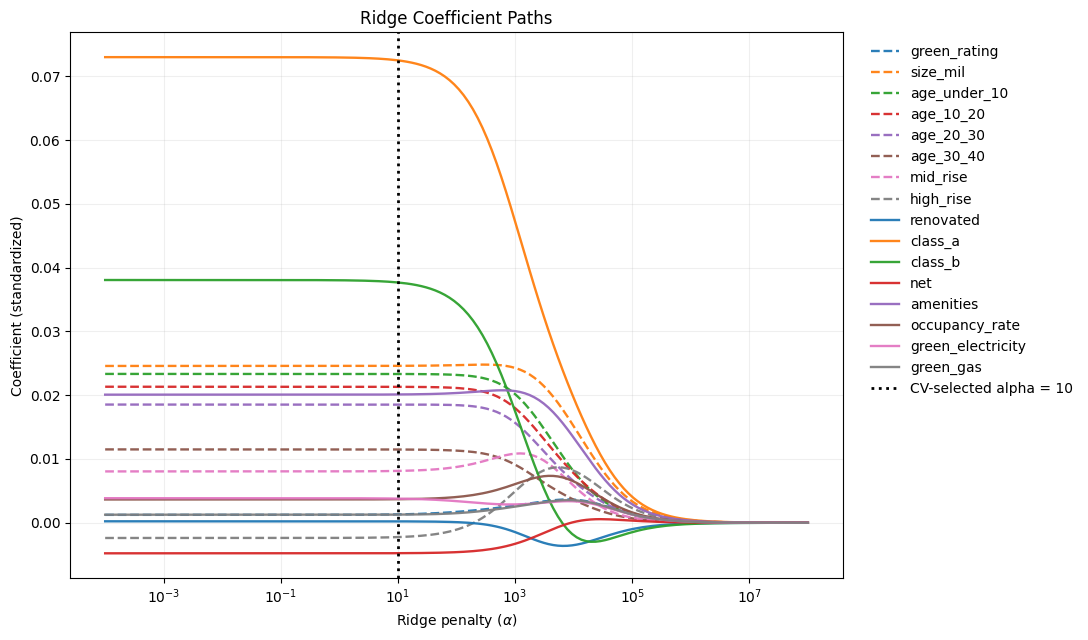

In [925]:
fig, ax = plt.subplots(figsize=(11, 6.5))

# Eight distinct colours
colors = plt.cm.tab10(np.arange(8))

for j, variable in enumerate(X_train.columns):
    color_idx = j % 8

    # First 8: patterned; second 8: solid
    linestyle = "--" if j < 8 else "-"

    ax.plot(
        alphas,
        coefficient_paths[:, j],
        color=colors[color_idx],
        linestyle=linestyle,
        linewidth=1.7,
        alpha=0.95,
        label=variable,
    )

ax.axvline(
    best_alpha,
    color="black",
    linestyle=":",
    linewidth=2,
    label=f"CV-selected alpha = {best_alpha:.3g}",
)

ax.set_xscale("log")
ax.set_xlabel(r"Ridge penalty ($\alpha$)")
ax.set_ylabel("Coefficient (standardized)")
ax.set_title("Ridge Coefficient Paths")
ax.grid(True, alpha=0.2)

ax.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=10,
    frameon=False,
)

plt.tight_layout()
plt.show()

In [845]:

ridge_coefficients = pd.DataFrame({
    "Variable": X_train.columns,
    "Ridge coefficient": best_ridge_model.named_steps["ridge"].coef_
})

ridge_coefficients["Absolute coefficient"] = (
    ridge_coefficients["Ridge coefficient"].abs()
)

ridge_coefficients = ridge_coefficients.sort_values(
    "Absolute coefficient", ascending=False
).reset_index(drop=True)

ridge_coefficients = ridge_coefficients[
    ["Variable", "Ridge coefficient", "Absolute coefficient"]
]

ridge_coefficients.round(4)


,Variable,Ridge coefficient,Absolute coefficient
0,class_a,0.0725,0.0725
1,class_b,0.0377,0.0377
2,size_mil,0.0246,0.0246
3,age_under_10,0.0233,0.0233
4,age_10_20,0.0213,0.0213
5,amenities,0.0201,0.0201
6,age_20_30,0.0185,0.0185
7,age_30_40,0.0115,0.0115
8,mid_rise,0.0081,0.0081
9,net,-0.0048,0.0048


In [846]:
# Generate LaTeX table
latex_table = ridge_coefficients.round(3).to_latex(
    index=False,
    escape=True,
    column_format="lrrrrrr",
    caption="Ridge Coefficients",
    label="tab:ridge_coef",
    na_rep="--",
)
with open("ridge_coef.tex", "w") as f:
    f.write(latex_table)

print(latex_table)

\begin{table}
\caption{Ridge Coefficients}
\label{tab:ridge_coef}
\begin{tabular}{lrrrrrr}
\toprule
Variable & Ridge coefficient & Absolute coefficient \\
\midrule
class\_a & 0.073000 & 0.073000 \\
class\_b & 0.038000 & 0.038000 \\
size\_mil & 0.025000 & 0.025000 \\
age\_under\_10 & 0.023000 & 0.023000 \\
age\_10\_20 & 0.021000 & 0.021000 \\
amenities & 0.020000 & 0.020000 \\
age\_20\_30 & 0.019000 & 0.019000 \\
age\_30\_40 & 0.011000 & 0.011000 \\
mid\_rise & 0.008000 & 0.008000 \\
net & -0.005000 & 0.005000 \\
green\_electricity & 0.004000 & 0.004000 \\
occupancy\_rate & 0.004000 & 0.004000 \\
high\_rise & -0.002000 & 0.002000 \\
green\_rating & 0.001000 & 0.001000 \\
green\_gas & 0.001000 & 0.001000 \\
renovated & 0.000000 & 0.000000 \\
\bottomrule
\end{tabular}
\end{table}



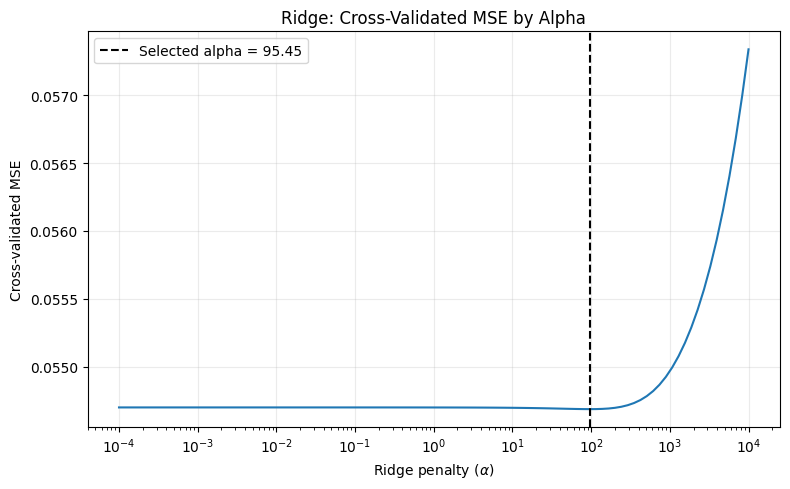

In [847]:
ridge_cv = pd.DataFrame({
    "alpha": search.cv_results_["param_ridge__alpha"].data.astype(float),
    "CV_MSE": -search.cv_results_["mean_test_score"]
}).sort_values("alpha")

best_ridge_alpha = search.best_params_["ridge__alpha"]

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(ridge_cv["alpha"], ridge_cv["CV_MSE"])
ax.axvline(
    best_ridge_alpha,
    color="black",
    linestyle="--",
    label=f"Selected alpha = {best_ridge_alpha:.4g}"
)

ax.set_xscale("log")
ax.set_xlabel(r"Ridge penalty ($\alpha$)")
ax.set_ylabel("Cross-validated MSE")
ax.set_title("Ridge: Cross-Validated MSE by Alpha")
ax.legend()
ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

## Lasso

### Old approach

In [848]:
""" lassoCV = skl.ElasticNetCV(
    n_alphas=100,
    l1_ratio=1,
    cv=kfold
)

pipe_cv = Pipeline(
    steps=[('scaler', scaler), ('lasso', lassoCV)]
)
pipe_cv.fit(X_demeaned, y_demeaned)
tuned_lasso = pipe_cv.named_steps['lasso']
tuned_lasso.alpha_ """;

In [849]:
""" scaler_fitted = pipe_cv.named_steps['scaler']
X_demeaned_scaled = scaler_fitted.transform(X_demeaned) """;

In [850]:
""" alphas, soln_array = skl.Lasso.path(X_demeaned_scaled,
                                    y_demeaned,
                                    l1_ratio=1,
                                    n_alphas=100)[:2]
soln_path = pd.DataFrame(soln_array.T,
                         columns=X_demeaned.columns,
                         index=-np.log(alphas)) """;

In [851]:
""" path_fig, ax = subplots(figsize=(8,8))
soln_path.plot(ax=ax, legend=False)
ax.legend(loc='upper left')
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Standardized coefficients', fontsize=20);
 """;

In [852]:
""" lassoCV_fig, ax = subplots(figsize=(8,8))
ax.errorbar(-np.log(tuned_lasso.alphas_),
            tuned_lasso.mse_path_.mean(1),
            yerr=tuned_lasso.mse_path_.std(1) / np.sqrt(K))
ax.axvline(-np.log(tuned_lasso.alpha_), c='k', ls='--')
# ax.set_ylim([50000,250000])
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Cross-validated MSE', fontsize=20); """;

### New approach

In [853]:

# Candidate penalty values
alphas = np.logspace(-5, 1, 100)

# Five-fold CV (same folds as Ridge)
cv = KFold(n_splits=5, shuffle=True, random_state=42)

lasso_pipeline = Pipeline([
    ("scaler", StandardScaler(with_mean=False)),
    ("lasso", Lasso(max_iter=100000, fit_intercept=False))
])

lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid={"lasso__alpha": alphas},
    scoring="neg_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

lasso_search.fit(X_train, y_train)

best_lasso_alpha = lasso_search.best_params_["lasso__alpha"]
best_lasso_model = lasso_search.best_estimator_

print(f"Selected alpha: {best_lasso_alpha:.6g}")
print(f"Best CV MSE: {-lasso_search.best_score_:.6f}")
print(f"Best CV RMSE: {np.sqrt(-lasso_search.best_score_):.4f}")

# Coefficient table
lasso_coefs = best_lasso_model.named_steps["lasso"].coef_

lasso_results = pd.DataFrame({
    "Variable": X_train.columns,
    "LASSO coefficient": lasso_coefs
})

lasso_results["Absolute coefficient"] = (
    lasso_results["LASSO coefficient"].abs()
)

lasso_results = lasso_results.sort_values(
    "Absolute coefficient", ascending=False
)

display(lasso_results.round(4))

print(
    f"Number of coefficients set to zero: "
    f"{np.sum(lasso_coefs == 0)} out of {len(lasso_coefs)}"
)

Selected alpha: 0.000497702
Best CV MSE: 0.053594
Best CV RMSE: 0.2315


,Variable,LASSO coefficient,Absolute coefficient
9,class_a,0.0719,0.0719
10,class_b,0.0365,0.0365
1,size_mil,0.0240,0.0240
2,age_under_10,0.0223,0.0223
3,age_10_20,0.0200,0.0200
12,amenities,0.0198,0.0198
4,age_20_30,0.0170,0.0170
5,age_30_40,0.0102,0.0102
6,mid_rise,0.0085,0.0085
11,net,-0.0042,0.0042


Number of coefficients set to zero: 1 out of 16


In [854]:
from pathlib import Path

# Prepare table for LaTeX
latex_table = lasso_results[["Variable", "LASSO coefficient"]].copy()
latex_table["LASSO coefficient"] = latex_table["LASSO coefficient"].map(
    lambda x: f"{x:.4f}"
)

# Export to LaTeX
latex_output = latex_table.to_latex(
    index=False,
    escape=True,
    column_format="lr",
    caption="LASSO Regression Coefficients",
    label="tab:lasso_coefficients",
    bold_rows=False,
)

with open("lasso_coef.tex", "w") as f:
    f.write(latex_output)

In [855]:
y_pred_lasso = best_lasso_model.predict(X_test)

test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lasso))

print(f'test RMSE:{test_rmse:.4f}')

test RMSE:0.2660


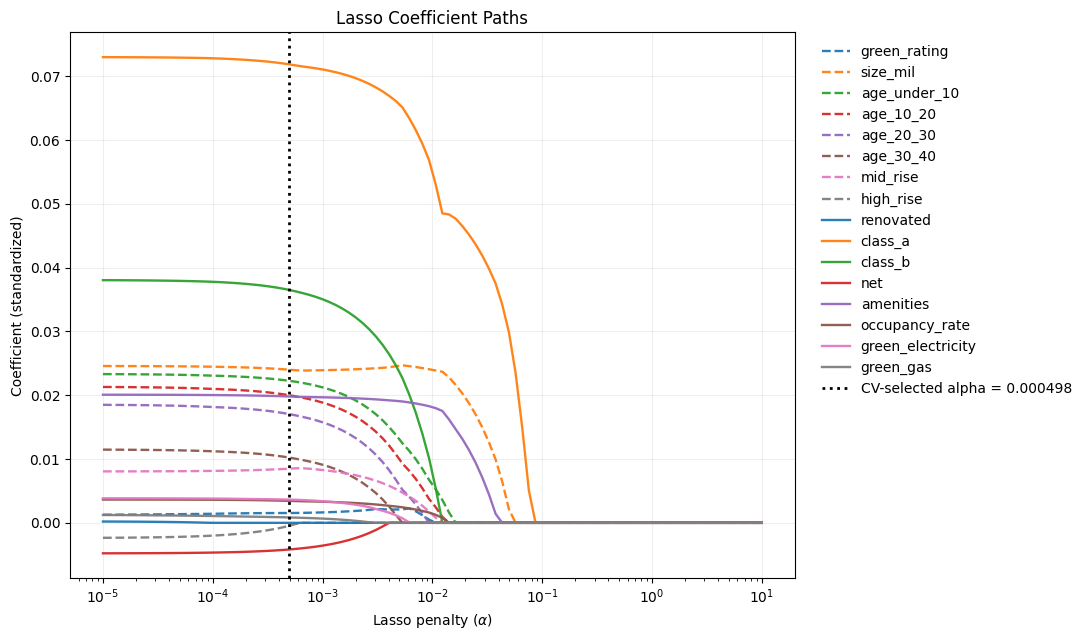

In [920]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import lasso_path

scaler_path = StandardScaler(with_mean=False)
X_train_scaled_path = scaler_path.fit_transform(X_train)

alphas_path, lasso_coefs_path, _ = lasso_path(
    X_train_scaled_path, y_train, alphas=alphas, max_iter=100000
)
lasso_coefs_path = lasso_coefs_path.T            # (n_alphas, n_features)

# lasso_path returns alphas largest -> smallest; flip both so penalty increases left to right
order = np.argsort(alphas_path)
alphas_path = alphas_path[order]
lasso_coefs_path = lasso_coefs_path[order]

fig, ax = plt.subplots(figsize=(11, 6.5))
colors = plt.cm.tab10(np.arange(8))

for j, variable in enumerate(X_train.columns):
    ax.plot(
        alphas_path,
        lasso_coefs_path[:, j],
        color=colors[j % 8],
        linestyle="--" if j < 8 else "-",
        linewidth=1.7,
        alpha=0.95,
        label=variable,
    )

ax.axvline(best_lasso_alpha, color="black", linestyle=":", linewidth=2,
           label=f"CV-selected alpha = {best_lasso_alpha:.3g}")

ax.set_xscale("log")
ax.set_xlabel(r"Lasso penalty ($\alpha$)")
ax.set_ylabel("Coefficient (standardized)")
ax.set_title("Lasso Coefficient Paths")
ax.grid(True, alpha=0.2)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=10, frameon=False)
plt.tight_layout()
plt.show()

In [857]:
lasso_coefs

array([ 0.00148746,  0.02400284,  0.02225951,  0.01999665,  0.0170408 ,
        0.01022444,  0.00848474, -0.00046298, -0.        ,  0.07186993,
        0.03650863, -0.00417581,  0.01980467,  0.00344228,  0.00369513,
        0.00084521])

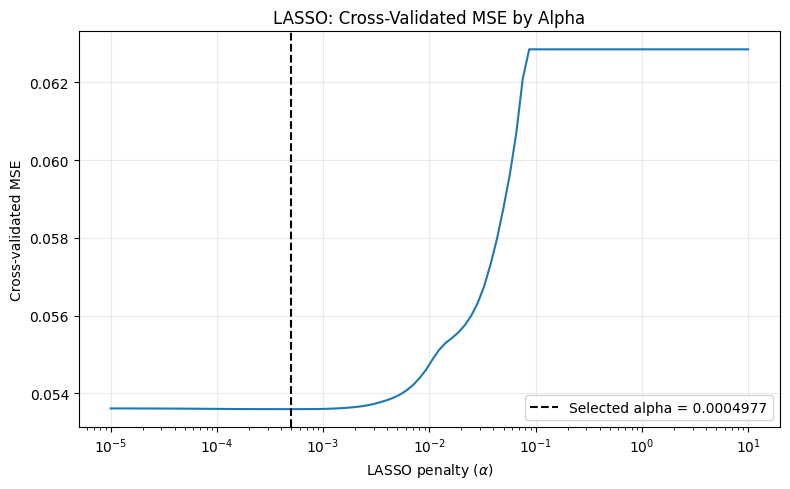

In [858]:
lasso_cv = pd.DataFrame({
    "alpha": lasso_search.cv_results_["param_lasso__alpha"].data.astype(float),
    "CV_MSE": -lasso_search.cv_results_["mean_test_score"]
}).sort_values("alpha")

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(lasso_cv["alpha"], lasso_cv["CV_MSE"])
ax.axvline(
    best_lasso_alpha,
    color="black",
    linestyle="--",
    label=f"Selected alpha = {best_lasso_alpha:.4g}"
)

ax.set_xscale("log")
ax.set_xlabel(r"LASSO penalty ($\alpha$)")
ax.set_ylabel("Cross-validated MSE")
ax.set_title("LASSO: Cross-Validated MSE by Alpha")
ax.legend()
ax.grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

## Draft takeaways from regularization

I fit ridge and lasso to within-cluster de-meaned log rent using 16 building-level predictors, tuning the penalty by 5-fold cross-validation on the training set. Both models reach essentially identical cross-validated MSE (about 0.0547, RMSE about 0.234), and their coefficients are nearly the same, so regularization does little work here: with 16 predictors and roughly 5,900 training rows, the penalized fits sit very close to OLS. The models agree on which characteristics matter most for rent differences between nearby buildings: Class A (standardized coefficient about 0.07) and Class B (about 0.03) status dominate, followed by size, building age (newer buildings earn more), and amenities, while net leases are associated with lower rent. Renovation status, gas-related green indicators and the leasing rate contribute little. The green rating coefficient is set to zero by lasso and is close to zero under ridge (0.0005), so certification adds almost nothing to out-of-sample prediction once these other characteristics are included. This should not be read as evidence of no green premium: a premium of a few percent on a binary indicator that applies to under 10% of buildings explains only a tiny share of rent variance, so a prediction-focused penalty will drop it even if the effect is economically meaningful. Estimating the premium requires a method that does not penalize or discard the treatment, such as OLS or post-double-selection lasso.

# Report 4

## Decision Tree

In [859]:
tree = DTR(random_state=seed)

In [860]:
param_grid = {
    'ccp_alpha': [0.0, *np.logspace(-10, -4, 12)],
    'max_depth': [3],
    'min_samples_leaf': [5, 10, 25, 50],
    'min_samples_split': [2, 10, 25]
}

tree_cv = skm.GroupKFold(n_splits=5)
grid_tree = skm.GridSearchCV(
    DTR(random_state=seed),
    param_grid=param_grid,
    cv=tree_cv,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    verbose=1
)
G = grid_tree.fit(X_train, y_train, groups=train['id'])
best_tree = grid_tree.best_estimator_

print(f'Best grouped CV MSE: {-grid_tree.best_score_:,.4f}')
print(f'Best parameters: {grid_tree.best_params_}')

Fitting 5 folds for each of 156 candidates, totalling 780 fits
Best grouped CV MSE: 0.0544
Best parameters: {'ccp_alpha': 0.0, 'max_depth': 3, 'min_samples_leaf': 5, 'min_samples_split': 2}


In [861]:
tree_mse = mean_squared_error(y_test, best_tree.predict(X_test))
tree_rmse = np.sqrt(tree_mse)

print(f'Test MSE: {tree_mse:.4f}')
print(f'Test RMSE: {tree_rmse:.4f}')

Test MSE: 0.0716
Test RMSE: 0.2676


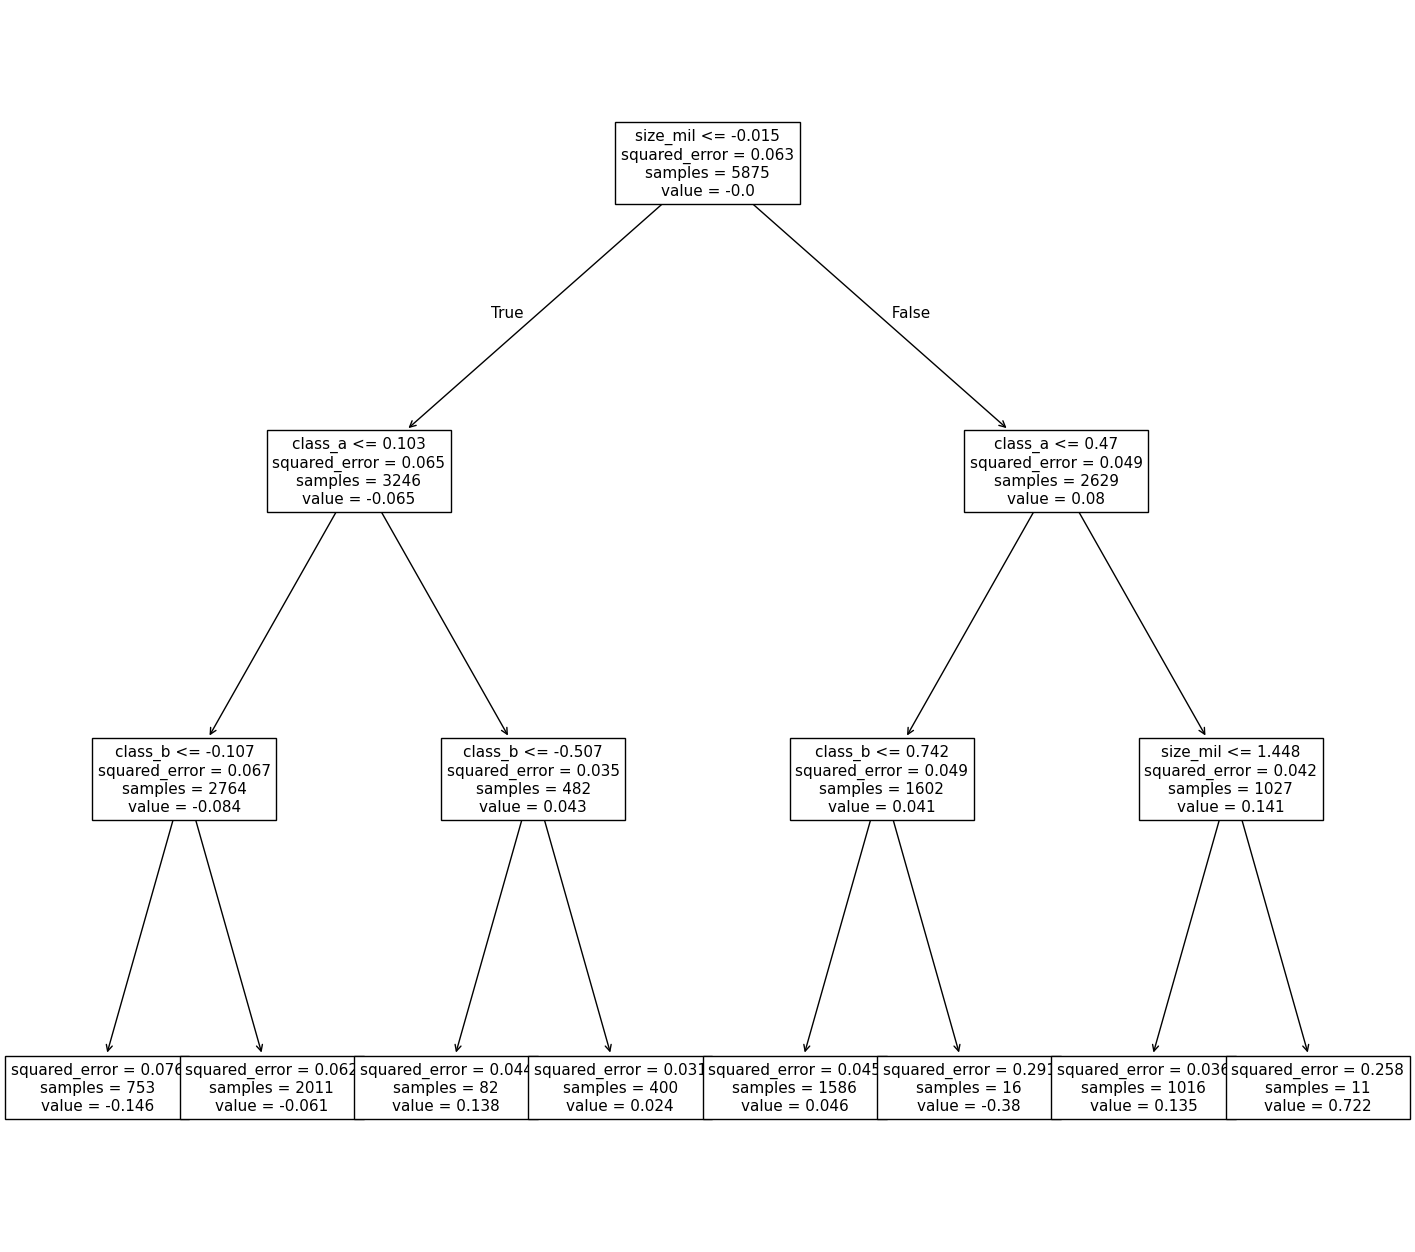

In [927]:
ax = subplots(figsize=(18, 16))[1]
plot_tree(best_tree, feature_names=X_train.columns, ax=ax, fontsize=11);

In [863]:
tree_feature_imp = pd.DataFrame(
    {'importance':best_tree.feature_importances_},
    index=X_train.columns)
tree_feature_imp.sort_values(by='importance', ascending=False)

,importance
size_mil,0.626433
class_a,0.234553
class_b,0.139013
green_rating,0.000000
age_under_10,0.000000
age_10_20,0.000000
age_20_30,0.000000
age_30_40,0.000000
mid_rise,0.000000
high_rise,0.000000


## Random Forest

### New


In [864]:
n_features = X_train.shape[1]

# Settings to try
rf_param_grid = {
    'max_features': [2, 3, 5, 8],
    'min_samples_leaf': [1, 3, 5, 10, 20, 40],
    'max_samples': [0.5, 0.8, None]
}

# Grouped 5-fold CV: whole clusters are held out together
rf_search = skm.GridSearchCV(
    RF(n_estimators=300, random_state=seed),
    param_grid=rf_param_grid,
    cv=skm.GroupKFold(n_splits=5),
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    verbose=1
)
rf_search.fit(X_train, y_train, groups=train['id'])

print(f'Best parameters: {rf_search.best_params_}')
print(f'Grouped CV MSE: {-rf_search.best_score_:.4f}')

# Refit the best settings with more trees on all training data
rf = RF(n_estimators=1000, random_state=seed, n_jobs=-1, **rf_search.best_params_)
rf.fit(X_train, y_train)

# Evaluate once on the held-out test set
rf_test_mse = mean_squared_error(y_test, rf.predict(X_test))
rf_test_rmse = np.sqrt(rf_test_mse)

print(f'Test MSE: {rf_test_mse:.4f}')
print(f'Test RMSE: {rf_test_rmse:.4f}')

Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best parameters: {'max_features': 8, 'max_samples': None, 'min_samples_leaf': 1}
Grouped CV MSE: 0.0448
Test MSE: 0.0613
Test RMSE: 0.2476


In [865]:
from sklearn.inspection import permutation_importance

# 1. Built-in importance: how much each variable reduced prediction error inside the trees
impurity_importance = pd.Series(rf.feature_importances_, index=X_train.columns)

# 2. Permutation importance: how much test MSE rises when the variable is shuffled
perm = permutation_importance(
    rf, X_test, y_test,
    n_repeats=30,
    scoring='neg_mean_squared_error',
    random_state=seed,
    n_jobs=-1
)
perm_importance = pd.Series(perm.importances_mean, index=X_test.columns)
perm_sd = pd.Series(perm.importances_std, index=X_test.columns)

importance_table = pd.DataFrame({
    'Impurity importance': impurity_importance,
    'Permutation importance': perm_importance,
    'Permutation SD': perm_sd,
}).sort_values('Permutation importance', ascending=False)

importance_table.round(5)

/opt/anaconda3/envs/pydata/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,Impurity importance,Permutation importance,Permutation SD
size_mil,0.18027,0.01478,0.00152
class_a,0.10177,0.01181,0.00110
class_b,0.07088,0.00667,0.00074
occupancy_rate,0.12335,0.00423,0.00051
amenities,0.07877,0.00339,0.00043
renovated,0.07341,0.00210,0.00040
age_20_30,0.06532,0.00155,0.00043
mid_rise,0.05438,0.00114,0.00033
high_rise,0.04624,0.00108,0.00024
age_under_10,0.02359,0.00084,0.00020


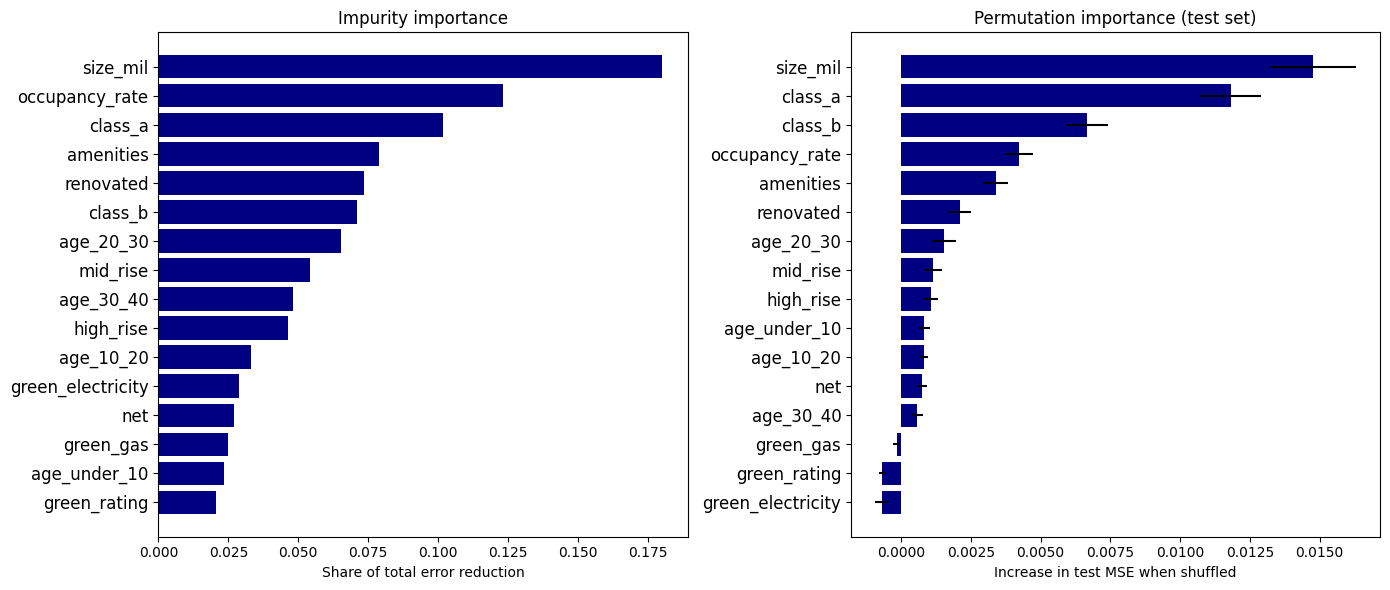

In [866]:
fig, axes = subplots(1, 2, figsize=(14, 6))

# Left: built-in importance
imp = impurity_importance.sort_values()
axes[0].barh(imp.index, imp.values, color='navy')
axes[0].set_title('Impurity importance')
axes[0].set_xlabel('Share of total error reduction')

# Right: permutation importance, with error bars (SD across the 30 shuffles)
perm_sorted = perm_importance.sort_values()
axes[1].barh(perm_sorted.index, perm_sorted.values,
             xerr=perm_sd[perm_sorted.index].values, color='navy')
axes[1].set_title('Permutation importance (test set)')
axes[1].set_xlabel('Increase in test MSE when shuffled')

for ax in axes:
    ax.tick_params(axis='y', labelsize=12)
fig.tight_layout()

Permutation importance ranks building size and Class A status as the most important predictors of within-cluster rent differences, followed by Class B, occupancy and amenities, with building age contributing through its several bins. The ranking broadly agrees with ridge and lasso on class and amenities, while the forest assigns more weight to size and occupancy, suggesting nonlinear structure. The built-in impurity importance overstates variables with many distinct values (occupancy, renovation, and the green interactions), so I rely on permutation importance. The three green variables have permutation importance indistinguishable from zero. Because they are highly correlated with each other and the premium is small relative to rent variation, this indicates that certification adds little predictive power, not that no premium exists.

### Old

In [550]:
""" rf = RF(max_features=5, random_state=seed)
rf_cv = skm.GroupKFold(n_splits=5)
rf_cv_scores = skm.cross_val_score(
    rf,
    X_train,
    y_train,
    groups=train['id'],
    cv=rf_cv,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)
rf_cv_mse = -rf_cv_scores
rf_cv_mse_mean = rf_cv_mse.mean()
rf_cv_mse_se = rf_cv_mse.std(ddof=1) / np.sqrt(len(rf_cv_mse))

rf.fit(X_train, y_train)
rf_test_predictions = rf.predict(X_test)
rf_test_mse = mean_squared_error(y_test, rf_test_predictions)
rf_test_rmse = np.sqrt(rf_test_mse)

print(f'Grouped CV MSE: {rf_cv_mse_mean:.4f} (SE: {rf_cv_mse_se:.4f})')
print(f'Test MSE: {rf_test_mse:.4f}')
print(f'Test RMSE: {rf_test_rmse:.4f}') """;

In [551]:
""" feature_imp = pd.DataFrame(
    {'importance':rf.feature_importances_},
    index=X_train.columns)
feature_imp.sort_values(by='importance', ascending=False) """;

In [552]:
""" rf_importance = pd.Series(
    rf.feature_importances_, index=X_train.columns, name='importance'
).sort_values()

fig, ax = subplots(figsize=(9, 6))
ax.barh(rf_importance.index, rf_importance.values, color='navy')
ax.set_title('Random Forest Feature Importance')
ax.set_xlabel('Importance')
ax.tick_params(axis='y', labelsize=12)
fig.tight_layout() """;

## Bagging Model

### New


In [868]:
# Bagging = many fully-grown-by-default trees on bootstrap samples, all features at every split
bag_param_grid = {
    'estimator__min_samples_leaf': [1, 3, 5, 10, 20, 40],   # minimum buildings per leaf in each tree
    'max_samples': [0.5, 0.7, 0.85, 1.0],                   # share of training rows in each bootstrap sample
}

bag_search = skm.GridSearchCV(
    BAG(
        estimator=DTR(random_state=seed),
        n_estimators=300,
        max_features=1.0,          # all variables available to every tree (this is what makes it bagging)
        bootstrap=True,
        random_state=seed,
        n_jobs=1
    ),
    param_grid=bag_param_grid,
    cv=skm.GroupKFold(n_splits=5),
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    verbose=1
)
bag_search.fit(X_train, y_train, groups=train['id'])

print(f'Best parameters: {bag_search.best_params_}')
print(f'Grouped CV MSE: {-bag_search.best_score_:.4f}')

# Refit the best settings with more trees on all training data
best_leaf = bag_search.best_params_['estimator__min_samples_leaf']
best_max_samples = bag_search.best_params_['max_samples']

bagging_model = BAG(
    estimator=DTR(min_samples_leaf=best_leaf, random_state=seed),
    n_estimators=1000,
    max_samples=best_max_samples,
    max_features=1.0,
    bootstrap=True,
    random_state=seed,
    n_jobs=-1
)
bagging_model.fit(X_train, y_train)

# Evaluate once on the held-out test set
bagging_test_mse = mean_squared_error(y_test, bagging_model.predict(X_test))
bagging_test_rmse = np.sqrt(bagging_test_mse)

print(f'Test MSE: {bagging_test_mse:.4f}')
print(f'Test RMSE: {bagging_test_rmse:.4f}')

Fitting 5 folds for each of 24 candidates, totalling 120 fits


Best parameters: {'estimator__min_samples_leaf': 1, 'max_samples': 1.0}
Grouped CV MSE: 0.0451
Test MSE: 0.0612
Test RMSE: 0.2473


In [869]:
from sklearn.inspection import permutation_importance

# 1. Built-in importance: average of each tree's own importance
#    (every tree sees all variables, so a plain average across trees works)
bag_impurity = pd.Series(
    np.mean([tree.feature_importances_ for tree in bagging_model.estimators_], axis=0),
    index=X_train.columns
)

# 2. Permutation importance: rise in test MSE when a variable is shuffled
bag_perm = permutation_importance(
    bagging_model, X_test, y_test,
    n_repeats=30,
    scoring='neg_mean_squared_error',
    random_state=seed,
    n_jobs=-1
)
bag_perm_importance = pd.Series(bag_perm.importances_mean, index=X_test.columns)
bag_perm_sd = pd.Series(bag_perm.importances_std, index=X_test.columns)

bag_importance_table = pd.DataFrame({
    'Impurity importance': bag_impurity,
    'Permutation importance': bag_perm_importance,
    'Permutation SD': bag_perm_sd,
}).sort_values('Permutation importance', ascending=False)

bag_importance_table.round(5)

/opt/anaconda3/envs/pydata/lib/python3.11/site-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,Impurity importance,Permutation importance,Permutation SD
size_mil,0.18891,0.01977,0.00218
class_a,0.10228,0.01324,0.00134
class_b,0.06847,0.00950,0.00109
occupancy_rate,0.12861,0.00455,0.00054
amenities,0.07950,0.00365,0.00040
renovated,0.07611,0.00257,0.00051
age_20_30,0.06727,0.00206,0.00048
mid_rise,0.05481,0.00130,0.00042
age_10_20,0.03212,0.00091,0.00014
age_under_10,0.02257,0.00086,0.00018


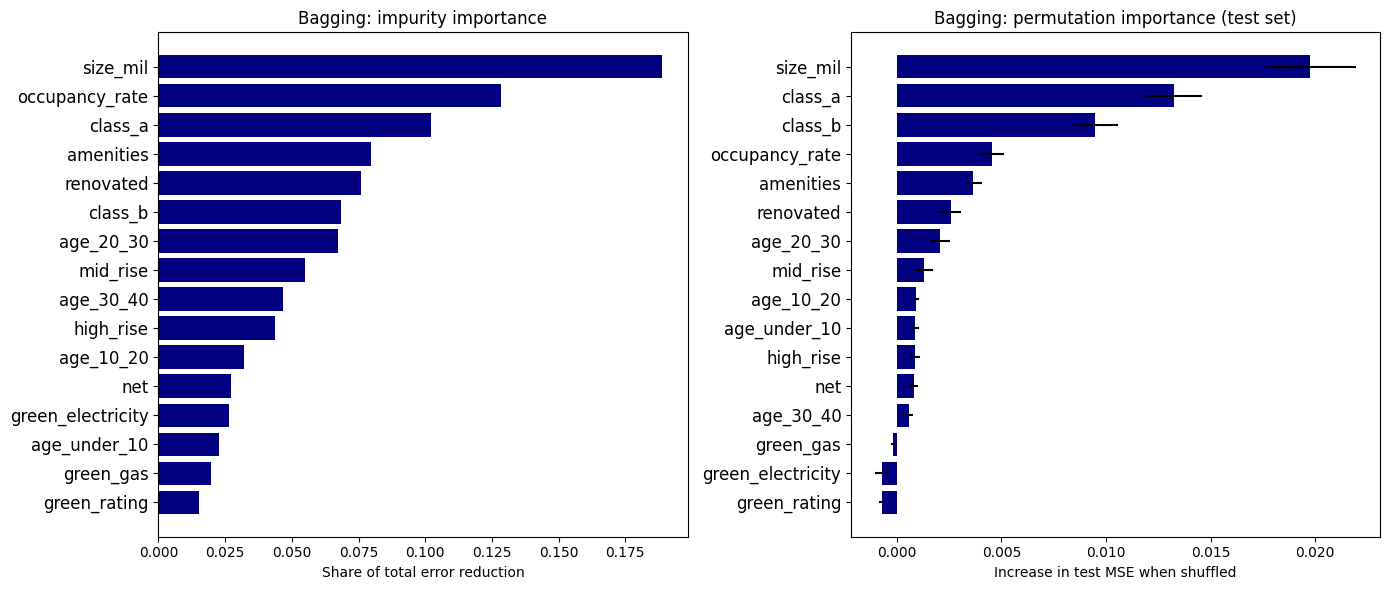

In [870]:
fig, axes = subplots(1, 2, figsize=(14, 6))

# Left: built-in importance
imp = bag_impurity.sort_values()
axes[0].barh(imp.index, imp.values, color='navy')
axes[0].set_title('Bagging: impurity importance')
axes[0].set_xlabel('Share of total error reduction')

# Right: permutation importance, with error bars (SD across the 30 shuffles)
perm_sorted = bag_perm_importance.sort_values()
axes[1].barh(perm_sorted.index, perm_sorted.values,
             xerr=bag_perm_sd[perm_sorted.index].values, color='navy')
axes[1].set_title('Bagging: permutation importance (test set)')
axes[1].set_xlabel('Increase in test MSE when shuffled')

for ax in axes:
    ax.tick_params(axis='y', labelsize=12)
fig.tight_layout()

### Old

In [556]:
""" bagging_model = BAG(
    estimator=DTR(max_features=None, random_state=seed),
    n_estimators=100,
    max_samples=1.0,
    max_features=1.0,
    bootstrap=True,
    random_state=seed,
    n_jobs=1
)

bagging_cv = skm.GroupKFold(n_splits=5)
bagging_cv_scores = skm.cross_val_score(
    bagging_model,
    X_train,
    y_train,
    groups=train['id'],
    cv=bagging_cv,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)
bagging_cv_mse = -bagging_cv_scores
bagging_cv_mse_mean = bagging_cv_mse.mean()
bagging_cv_mse_se = bagging_cv_mse.std(ddof=1) / np.sqrt(len(bagging_cv_mse))

bagging_model.fit(X_train, y_train)
bagging_test_predictions = bagging_model.predict(X_test)
bagging_test_mse = mean_squared_error(y_test, bagging_test_predictions)
bagging_test_rmse = np.sqrt(bagging_test_mse)

print(f'Grouped CV MSE: {bagging_cv_mse_mean:.4f} (SE: {bagging_cv_mse_se:.4f})')
print(f'Test MSE: {bagging_test_mse:.4f}')
print(f'Test RMSE: {bagging_test_rmse:.4f}') """;

In [557]:
""" bagging_importance_values = np.zeros(X_train.shape[1])
for estimator, feature_indices in zip(
    bagging_model.estimators_, bagging_model.estimators_features_
):
    bagging_importance_values[feature_indices] += estimator.feature_importances_
bagging_importance_values /= len(bagging_model.estimators_)

bagging_importance = pd.Series(
    bagging_importance_values,
    index=X_train.columns,
    name='importance'
).sort_values()

fig, ax = subplots(figsize=(9, 6))
ax.barh(bagging_importance.index, bagging_importance.values, color='navy')
ax.set_title('Bagging Feature Importance')
ax.set_xlabel('Mean importance across trees')
ax.tick_params(axis='y', labelsize=12)
fig.tight_layout() """;

## Boosting Model

In [871]:
param_dist = {
    'n_estimators':     [100, 200, 300, 500],
    'learning_rate':    [0.01, 0.03, 0.05, 0.1],
    'max_depth':        [2, 3, 4, 5],
    'min_samples_leaf': [5, 10, 25, 50],
    'subsample':        [0.5, 0.7, 1.0],
}

boost_search = skm.RandomizedSearchCV(
    GBR(random_state=seed),
    param_distributions=param_dist,
    n_iter=30,                       # ~150 fits; raise if time allows
    cv=skm.GroupKFold(n_splits=5),
    scoring='neg_mean_squared_error',
    n_jobs=-1, random_state=seed, verbose=1
)
boost_search.fit(X_train, y_train, groups=train['id'])

best_boost = boost_search.best_estimator_
print(boost_search.best_params_, np.sqrt(-boost_search.best_score_))

boost_test_mse = mean_squared_error(y_test, best_boost.predict(X_test))
print(f'Test MSE: {boost_test_mse:.4f}, RMSE: {np.sqrt(boost_test_mse):.4f}')

Fitting 5 folds for each of 30 candidates, totalling 150 fits
{'subsample': 0.7, 'n_estimators': 200, 'min_samples_leaf': 10, 'max_depth': 5, 'learning_rate': 0.05} 0.2214209964279693
Test MSE: 0.0646, RMSE: 0.2542


In [872]:
boosting_model = GBR(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=seed
)

boosting_cv = skm.GroupKFold(n_splits=5)
boosting_cv_scores = skm.cross_val_score(
    boosting_model,
    X_train,
    y_train,
    groups=train['id'],
    cv=boosting_cv,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)
boosting_cv_mse = -boosting_cv_scores
boosting_cv_mse_mean = boosting_cv_mse.mean()
boosting_cv_mse_se = boosting_cv_mse.std(ddof=1) / np.sqrt(len(boosting_cv_mse))

boosting_model.fit(X_train, y_train)
boosting_test_predictions = boosting_model.predict(X_test)
boosting_test_mse = mean_squared_error(y_test, boosting_test_predictions)
boosting_test_rmse = np.sqrt(boosting_test_mse)

print(f'Grouped CV MSE: {boosting_cv_mse_mean:.4f} (SE: {boosting_cv_mse_se:.4f})')
print(f'Test MSE: {boosting_test_mse:.4f}')
print(f'Test RMSE: {boosting_test_rmse:.4f}')

Grouped CV MSE: 0.0519 (SE: 0.0049)
Test MSE: 0.0759
Test RMSE: 0.2755


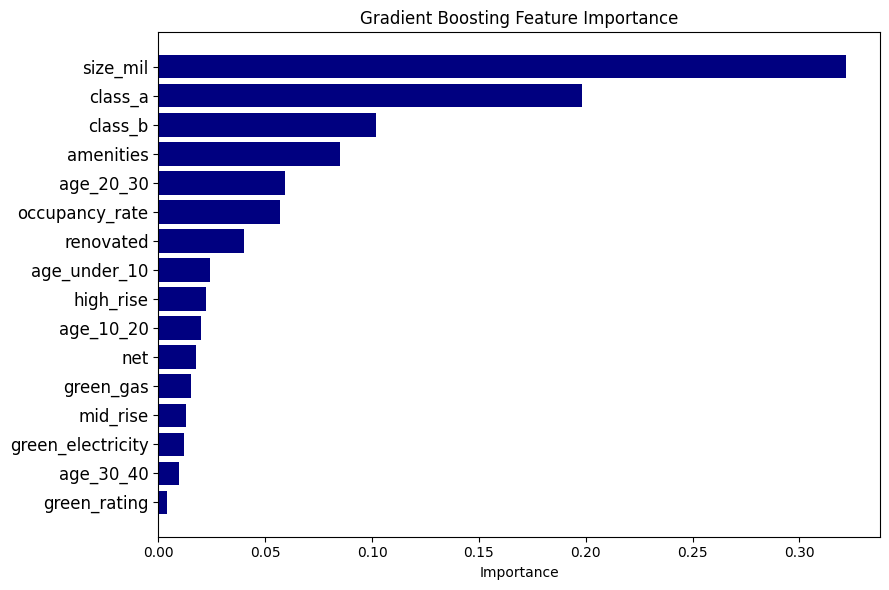

In [873]:
boosting_importance = pd.Series(
    boosting_model.feature_importances_,
    index=X_train.columns,
    name='importance'
).sort_values()

fig, ax = subplots(figsize=(9, 6))
ax.barh(boosting_importance.index, boosting_importance.values, color='navy')
ax.set_title('Gradient Boosting Feature Importance')
ax.set_xlabel('Importance')
ax.tick_params(axis='y', labelsize=12)
fig.tight_layout()

## Feature importance visual

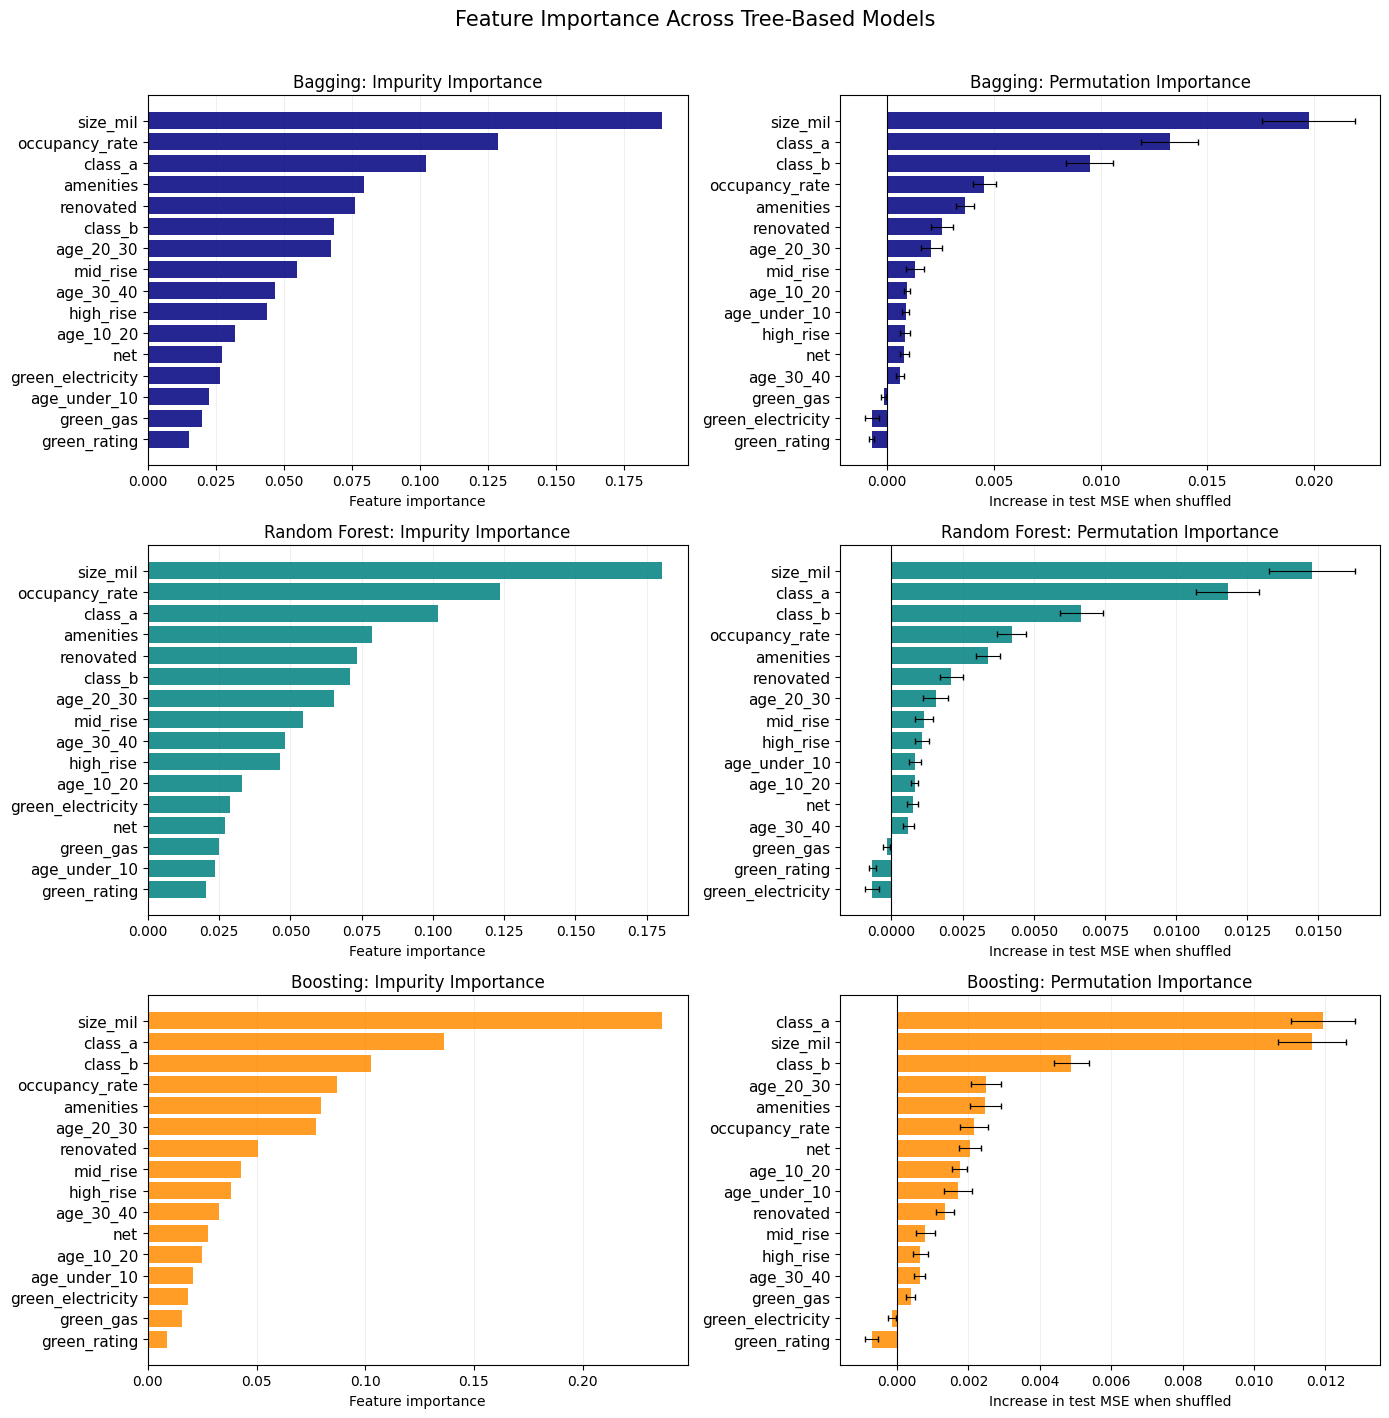

In [919]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from sklearn.inspection import permutation_importance

# --------------------------------------------------
# 1. Impurity importance
# --------------------------------------------------
impurity = {
    "Bagging": bag_impurity,
    "Random Forest": pd.Series(
        rf.feature_importances_, index=X_train.columns
    ),
    "Boosting": pd.Series(
        best_boost.feature_importances_, index=X_train.columns
    ),
}

# --------------------------------------------------
# 2. Permutation importance
# --------------------------------------------------
perm_means = {
    "Bagging": bag_perm_importance,
    "Random Forest": perm_importance,
}

perm_sds = {
    "Bagging": bag_perm_sd,
    "Random Forest": perm_sd,
}

# Calculate boosting permutation importance
boost_perm = permutation_importance(
    best_boost,
    X_test,
    y_test,
    n_repeats=30,
    scoring="neg_mean_squared_error",
    random_state=seed,
    n_jobs=-1,
)

perm_means["Boosting"] = pd.Series(
    boost_perm.importances_mean, index=X_test.columns
)
perm_sds["Boosting"] = pd.Series(
    boost_perm.importances_std, index=X_test.columns
)

# --------------------------------------------------
# 3. Common variable order: most to least important
# --------------------------------------------------
rankings = pd.DataFrame({
    model: values.rank(ascending=False)
    for model, values in perm_means.items()
})

variable_order = rankings.mean(axis=1).sort_values().index

# Reverse for barh so the most important appears at the top
variable_order = variable_order[::-1]

# --------------------------------------------------
# Plot: 3 rows x 2 columns
# Each panel sorted independently, most important at top
# --------------------------------------------------
model_names = ["Bagging", "Random Forest", "Boosting"]
model_colors = ["navy", "teal", "darkorange"]

fig, axes = plt.subplots(3, 2, figsize=(14, 14))

for i, (model_name, color) in enumerate(
    zip(model_names, model_colors)
):
    # Left: impurity importance, sorted independently
    ax = axes[i, 0]
    imp = impurity[model_name].sort_values(ascending=True)

    ax.barh(imp.index, imp.values, color=color, alpha=0.85)
    ax.set_title(f"{model_name}: Impurity Importance")
    ax.set_xlabel("Feature importance")
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

    # Right: permutation importance, sorted independently
    ax = axes[i, 1]
    perm = perm_means[model_name].sort_values(ascending=True)
    sd = perm_sds[model_name].reindex(perm.index)

    ax.barh(
        perm.index,
        perm.values,
        xerr=sd.values,
        color=color,
        alpha=0.85,
        error_kw={"elinewidth": 0.8, "capsize": 2},
    )
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_title(f"{model_name}: Permutation Importance")
    ax.set_xlabel("Increase in test MSE when shuffled")
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

for ax in axes.flat:
    ax.tick_params(axis="y", labelsize=11)


fig.suptitle(
    "Feature Importance Across Tree-Based Models",
    fontsize=15,
    y=1.01,
)

plt.tight_layout()
plt.show()

## Prediction Error Summary

In [913]:
from sklearn.metrics import mean_squared_error as mse

for name, m in {"Ridge": best_ridge_model, "Lasso": best_lasso_model}.items():
    print(name, type(m).__name__)
    if hasattr(m, "named_steps"):
        print("  steps:", list(m.named_steps))
    for label, Xtr, Xte in [("raw X", X_train, X_test),
                            ("scaled X", scaler_path.transform(X_train), scaler_path.transform(X_test))]:
        print(f"  {label:9s} train MSE {mse(y_train, m.predict(Xtr)):.4f} | test MSE {mse(y_test, m.predict(Xte)):.4f}")

Ridge Pipeline
  steps: ['scaler', 'ridge']
  raw X     train MSE 0.0533 | test MSE 0.0707
  scaled X  train MSE 0.9753 | test MSE 1.6515
Lasso Pipeline
  steps: ['scaler', 'lasso']
  raw X     train MSE 0.0533 | test MSE 0.0707
  scaled X  train MSE 0.6961 | test MSE 1.1687


/opt/anaconda3/envs/pydata/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pydata/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pydata/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/opt/anaconda3/envs/pydata/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [915]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

ols_model = LinearRegression(fit_intercept=False).fit(X_train, y_train)

models = {   # every model, including the ridge/lasso pipelines, takes raw X_test
    "OLS (cluster-demeaned)": ols_model,
    "Ridge":                  best_ridge_model,
    "Lasso":                  best_lasso_model,
    "Regression tree":        best_tree,
    "Bagging":                bagging_model,
    "Random forest":          rf,
    "Boosting":               best_boost,
}

rows = [("Null model (predict zero)", np.mean(np.asarray(y_test) ** 2))]
for name, m in models.items():
    rows.append((name, mean_squared_error(y_test, m.predict(X_test))))

df = pd.DataFrame(rows, columns=["Model", "Test MSE"])
df["Test RMSE"] = np.sqrt(df["Test MSE"])
df["MSE relative to null"] = df["Test MSE"] / df.loc[0, "Test MSE"]
display(df.round(4))

body = "".join(f"{a} & {b:.4f} & {c:.4f} & {d:.3f} \\\\\n"
               for a, b, c, d in df.itertuples(index=False, name=None))
tex = (
    "\\begin{table}[htbp]\n\\centering\n"
    "\\caption{Test-Set Prediction Error by Model}\n\\label{tab:mse_comparison}\n"
    "\\resizebox{\\ifdim\\width>\\textwidth\\textwidth\\else\\width\\fi}{!}{%\n"
    "\\begin{tabular}{lrrr}\n\\toprule\n"
    "Model & Test MSE & Test RMSE & MSE relative to null \\\\\n\\midrule\n"
    + body + "\\bottomrule\n\\end{tabular}}\n"
    "\\par\\vspace{0.5em}\\footnotesize \\textit{Notes:} Outcome is cluster-demeaned log rent. "
    "The null model predicts zero, the cluster average.\n\\end{table}\n"
)
with open("mse_comparison.tex", "w") as f:
    f.write(tex)

,Model,Test MSE,Test RMSE,MSE relative to null
0,Null model (predict zero),0.0850,0.2915,1.0000
1,OLS (cluster-demeaned),0.0707,0.2659,0.8323
2,Ridge,0.0707,0.2659,0.8323
3,Lasso,0.0707,0.2660,0.8327
4,Regression tree,0.0716,0.2676,0.8431
5,Bagging,0.0612,0.2473,0.7200
6,Random forest,0.0613,0.2476,0.7215
7,Boosting,0.0646,0.2542,0.7605


In [243]:
model_error_summary = pd.DataFrame([
    {
        'Model': 'Tree',
        'Test MSE': tree_mse,
        'Test RMSE': tree_rmse
    },
    {
        'Model': 'Bagging',
        'Test MSE': bagging_test_mse,
        'Test RMSE': bagging_test_rmse
    },
    {
        'Model': 'Random Forest',
        'Test MSE': rf_test_mse,
        'Test RMSE': rf_test_rmse
    },
    {
        'Model': 'Boosting',
        'Test MSE': boosting_test_mse,
        'Test RMSE': boosting_test_rmse
    }
]).set_index('Model')

model_error_summary.round(4)

NameError: name 'tree_mse' is not defined

In [164]:
summary_table_latex = model_error_summary.to_latex(index=True)
print(summary_table_latex)

\begin{tabular}{lrr}
\toprule
 & Test MSE & Test RMSE \\
Model &  &  \\
\midrule
Tree & 0.067803 & 0.260391 \\
Bagging & 0.054962 & 0.234440 \\
Random Forest & 0.053004 & 0.230227 \\
Boosting & 0.063121 & 0.251240 \\
\bottomrule
\end{tabular}



In [25]:
df_model.columns

Index(['green_rating', 'Rent', 'log_rent', 'size_000', 'age_under_10',
       'age_10_20', 'age_20_30', 'age_30_40', 'mid_rise', 'high_rise',
       'renovated', 'class_a', 'class_b', 'net', 'amenities', 'leasing_rate',
       'id'],
      dtype='object')

# Report 5

## Research Summary Rough Draft

This paper asks whether [green-certified office buildings command higher rents than otherwise comparable non-certified buildings / and whether this premium is larger where local energy costs are higher]. I use the building-level data from Eichholtz, Kok and Quigley (2010), [N = 7,820 buildings/observations, grouped into 679 local clusters]. The outcome is log rent per square foot (log_rent), and the treatment is green certification (green_rating). Covariates include age, size, stories, class, amenities, renovation status, contract type, [leasing rate, local employment growth]. I address selection into certification by [matching / adjusting] on observed covariates.



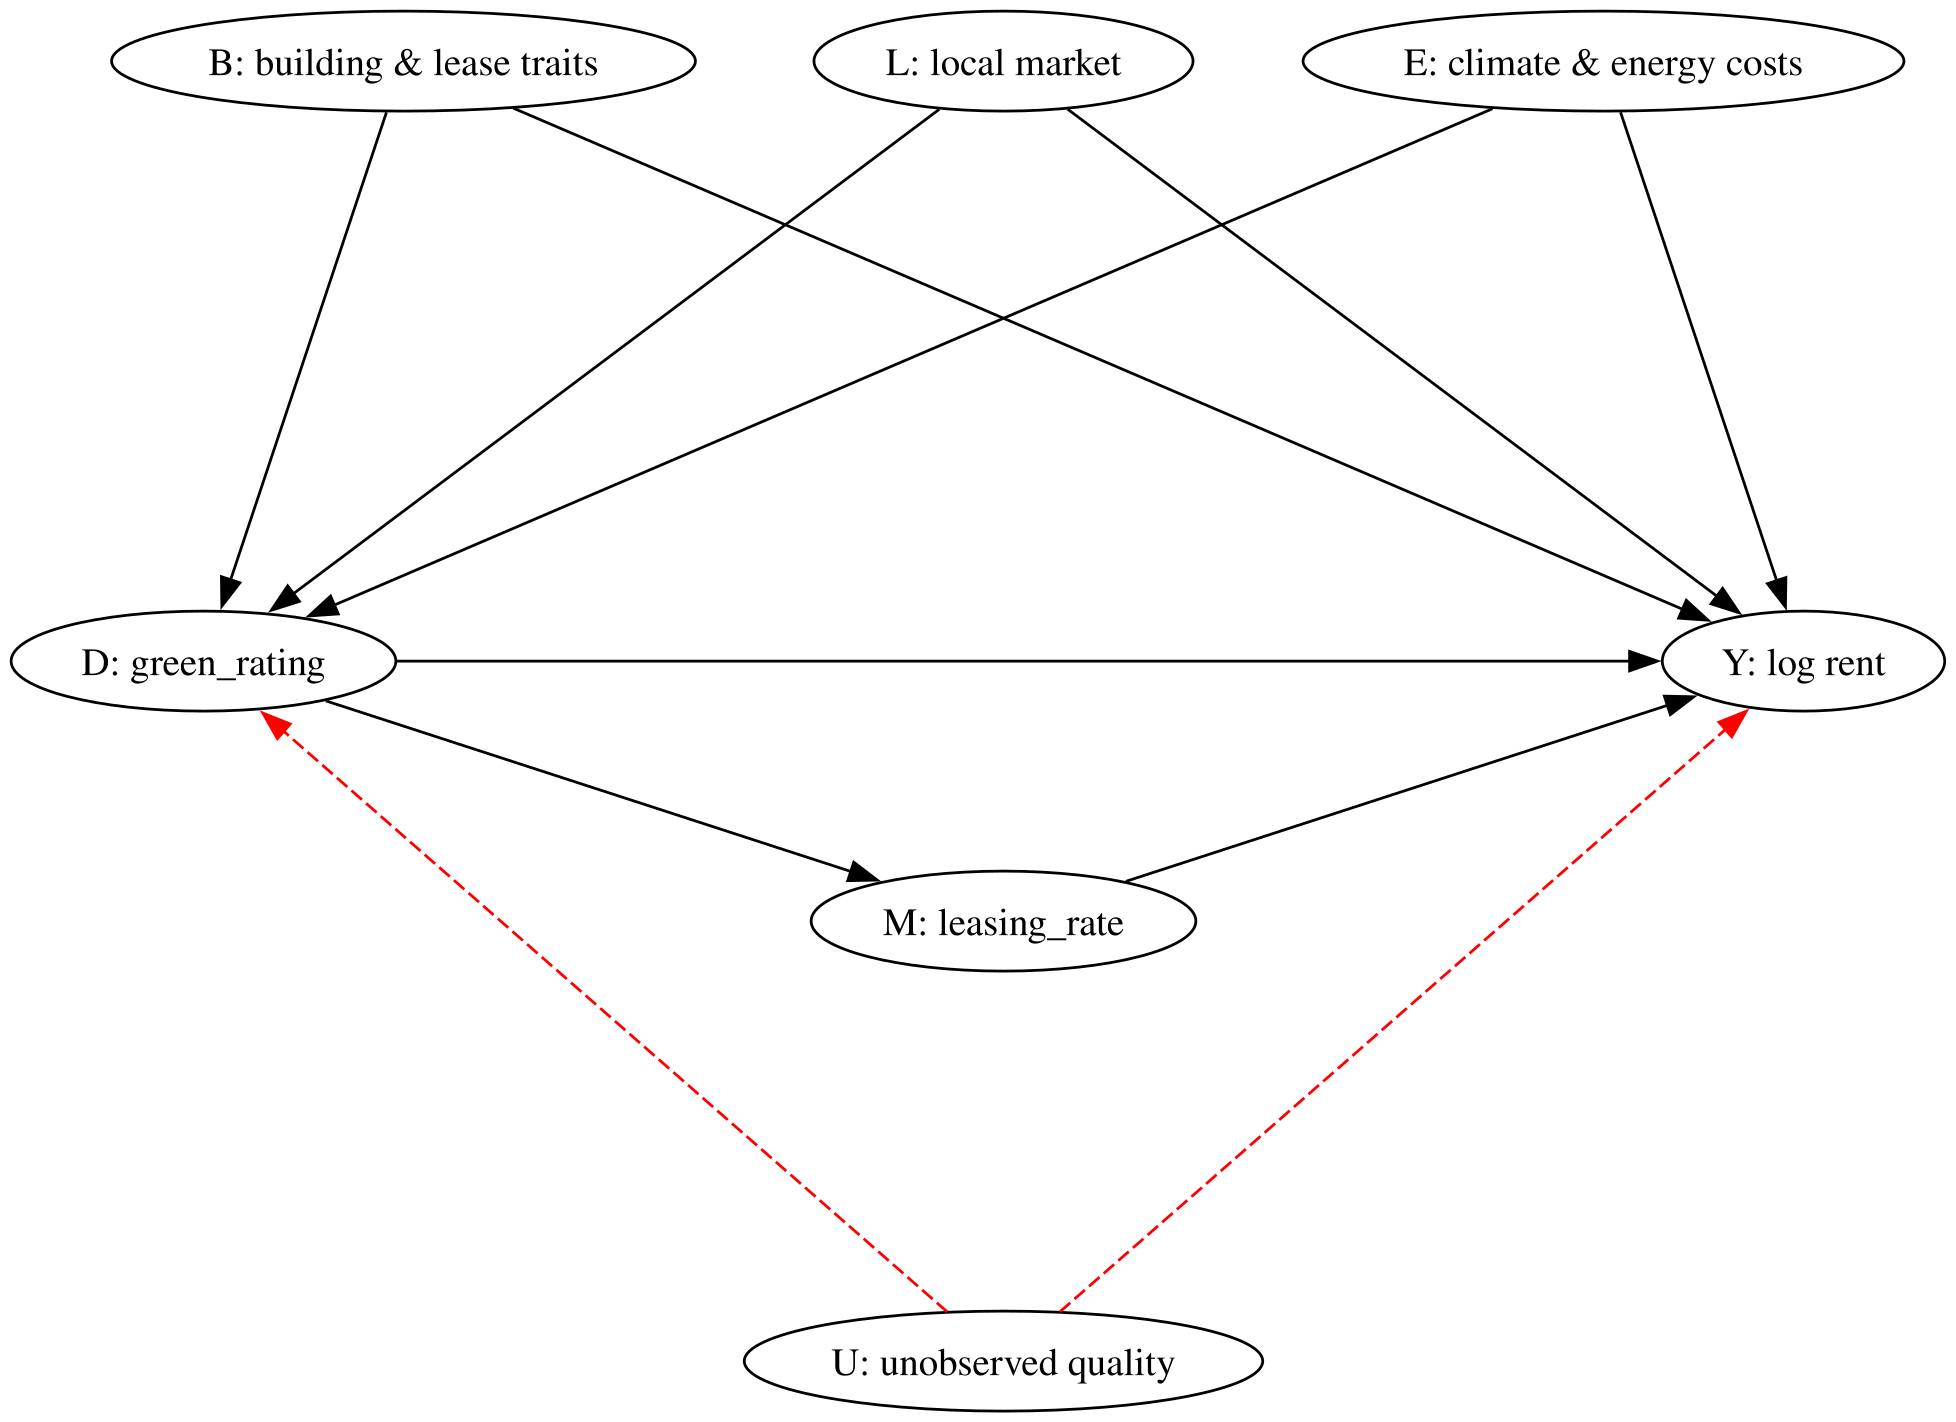

In [24]:
import os
import graphviz

os.makedirs('img', exist_ok=True)

graph = graphviz.Digraph(format='png', engine='neato')
graph.attr(dpi='200')

spec = {
    'D': ('D: green_rating',              '0,0!'),
    'Y': ('Y: log rent',                  '8,0!'),
    'B': ('B: building & lease traits',   '1,3!'),
    'L': ('L: local market',              '4,3!'),
    'E': ('E: climate & energy costs',    '7,3!'),
    'M': ('M: leasing_rate',              '4,-1.3!'),
    'U': ('U: unobserved quality',        '4,-3.5!'),
}

for n, (label, pos) in spec.items():
    graph.node(n, label=label, pos=pos)

# observed covariate groups affect both treatment and outcome
edges = ['BD', 'BY', 'LD', 'LY', 'ED', 'EY', 'DY', 'DM', 'MY']
graph.edges(edges)

# unobserved confounder: dashed and red
for e in ['UD', 'UY']:
    graph.edge(e[0], e[1], style='dashed', color='red')

graph.render('img/week5_dag', cleanup=True)
graph

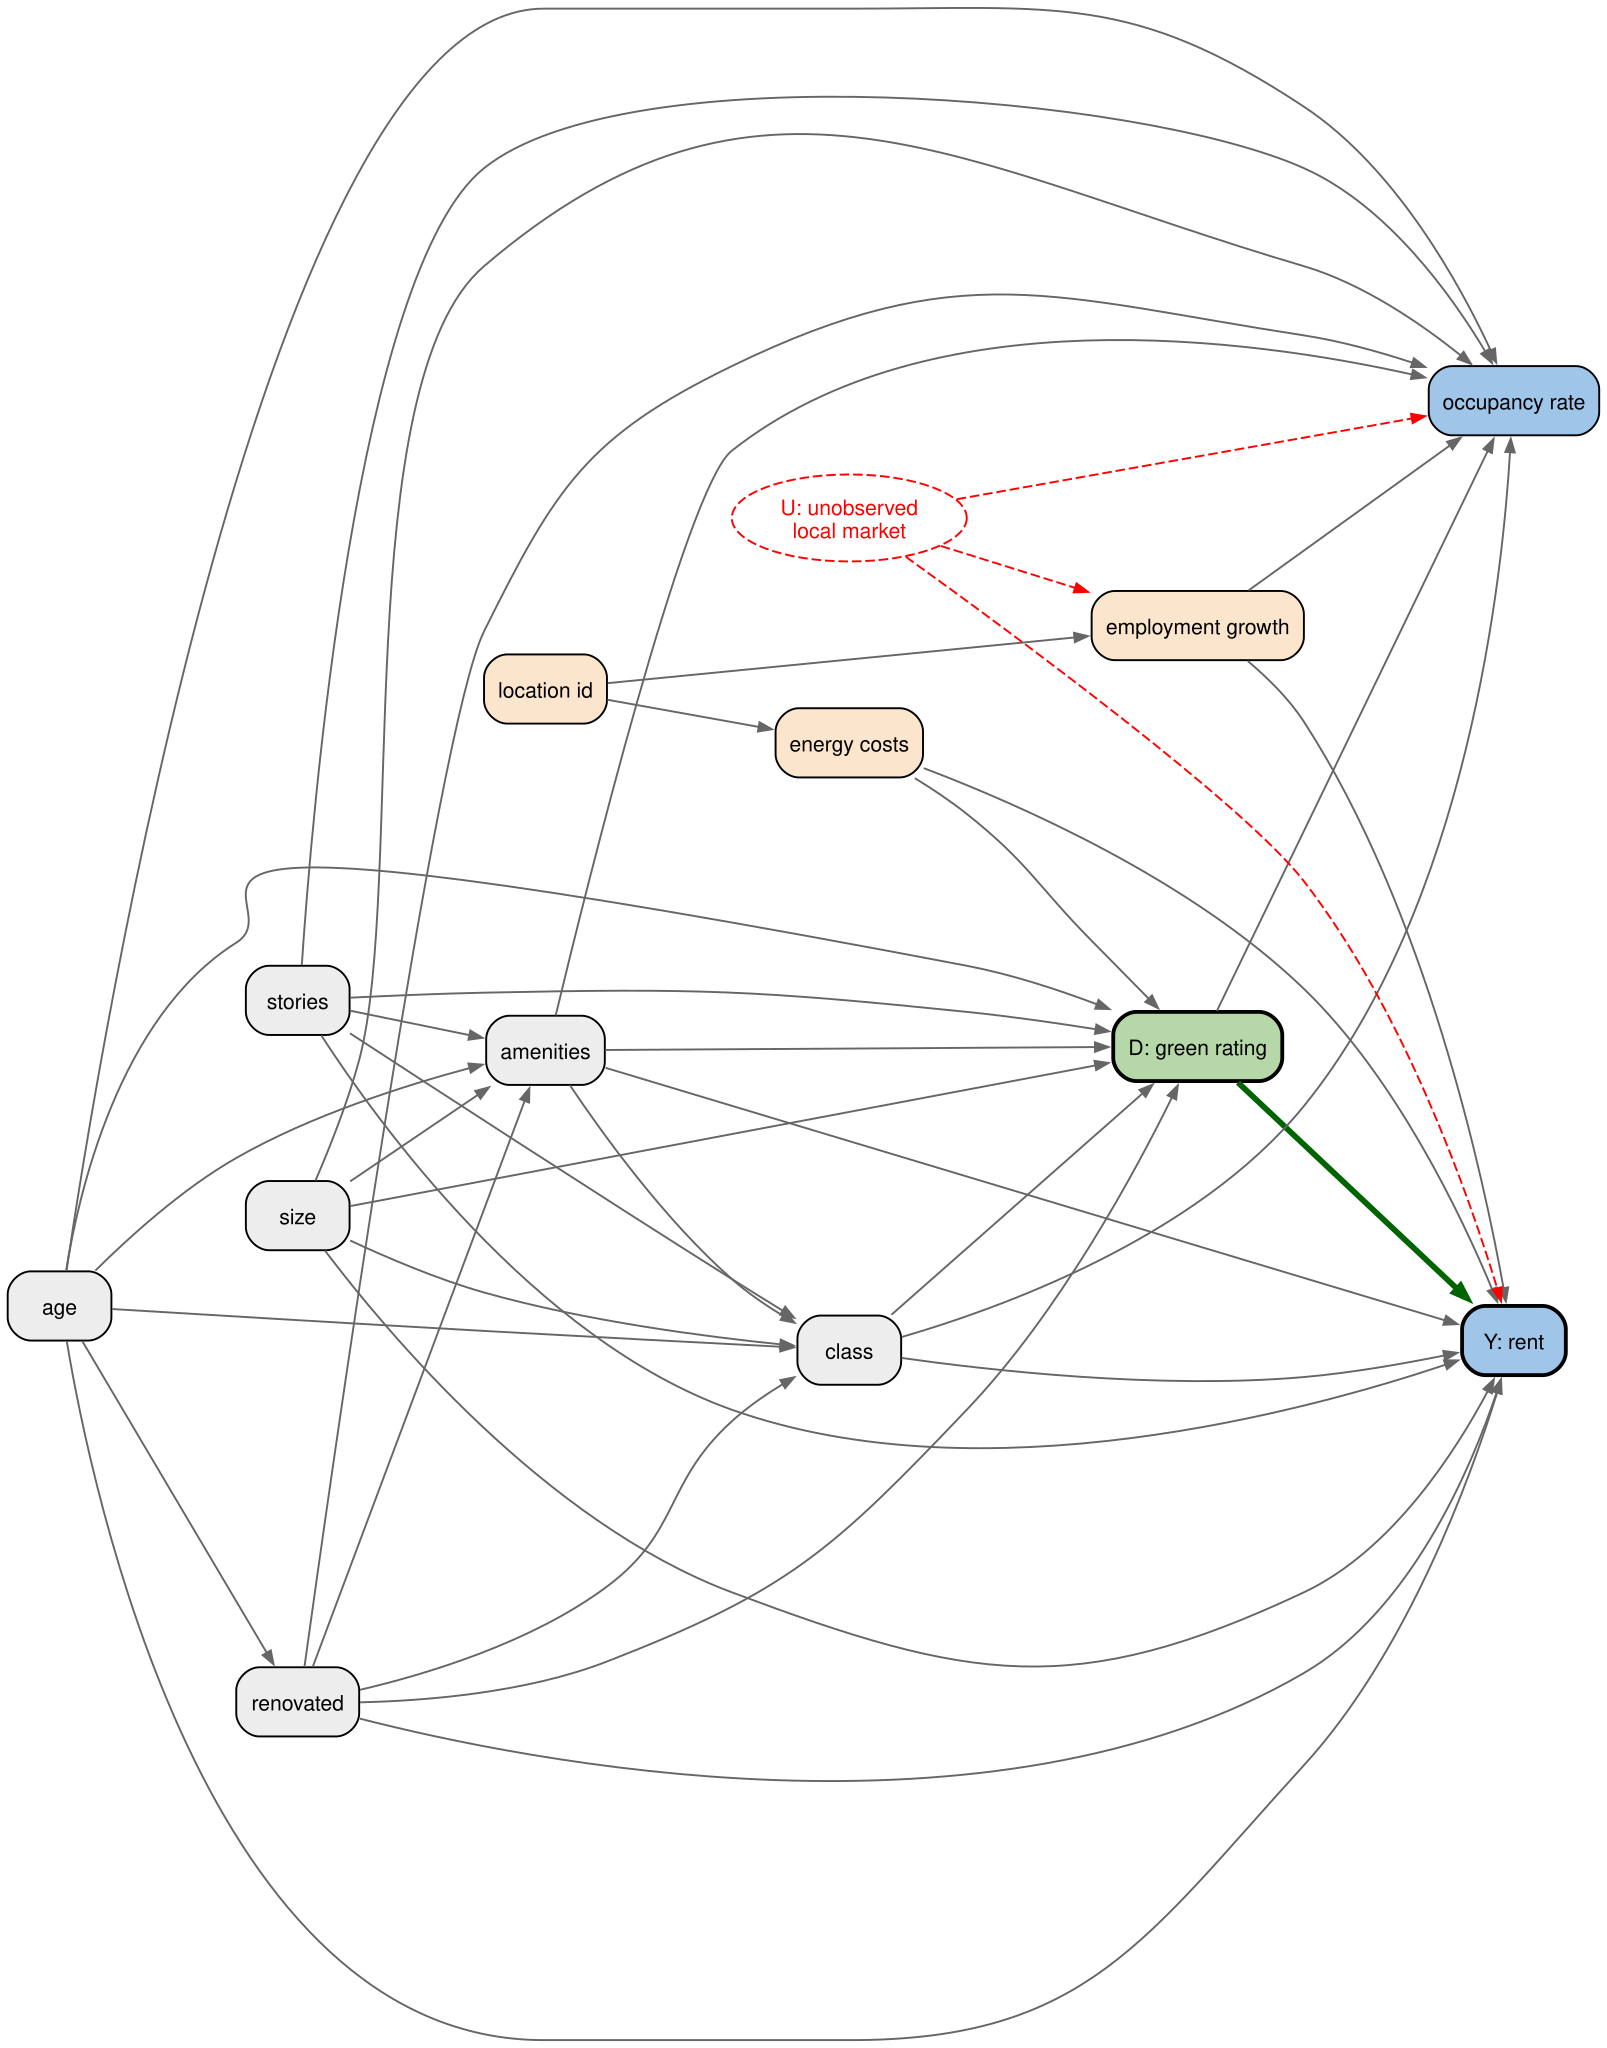

In [26]:
os.makedirs('img', exist_ok=True)

nodes = ['green rating', 'rent', 'size', 'age', 'stories', 'renovated', 'class',
         'amenities', 'occupancy rate', 'location id', 'employment growth',
         'energy costs', 'U_market']

# rows = cause, columns = effect (same order as `nodes`)
# with U_market -> energy costs and energy costs -> employment growth removed
A = [
    [0,1,0,0,0,0,0,0,1,0,0,0,0],  # green rating
    [0,0,0,0,0,0,0,0,0,0,0,0,0],  # rent
    [1,1,0,0,0,0,1,1,1,0,0,0,0],  # size
    [1,1,0,0,0,1,1,1,1,0,0,0,0],  # age
    [1,1,0,0,0,0,1,1,1,0,0,0,0],  # stories
    [1,1,0,0,0,0,1,1,1,0,0,0,0],  # renovated
    [1,1,0,0,0,0,0,0,1,0,0,0,0],  # class
    [1,1,0,0,0,0,1,0,1,0,0,0,0],  # amenities
    [0,0,0,0,0,0,0,0,0,0,0,0,0],  # occupancy rate
    [0,0,0,0,0,0,0,0,0,0,1,1,0],  # location id
    [0,1,0,0,0,0,0,0,1,0,0,0,0],  # employment growth
    [1,1,0,0,0,0,0,0,0,0,0,0,0],  # energy costs
    [0,1,0,0,0,0,0,0,1,0,1,0,0],  # U_market
]

building = {'size', 'age', 'stories', 'renovated', 'class', 'amenities'}
local    = {'location id', 'employment growth', 'energy costs'}

g = graphviz.Digraph(format='png', engine='dot')
g.attr(dpi='200', rankdir='LR', nodesep='0.35', ranksep='0.9')
g.attr('node', shape='box', style='rounded,filled', fontname='Helvetica', fontsize='11')
g.attr('edge', color='gray40', arrowsize='0.7')

for n in nodes:
    if n == 'green rating':
        g.node(n, label='D: green rating', fillcolor='#B6D7A8', penwidth='2')
    elif n == 'rent':
        g.node(n, label='Y: rent', fillcolor='#9FC5E8', penwidth='2')
    elif n == 'occupancy rate':
        g.node(n, label=n, fillcolor='#9FC5E8')
    elif n in building:
        g.node(n, fillcolor='#EDEDED')
    elif n in local:
        g.node(n, fillcolor='#FCE5CD')
    else:  # latent
        g.node(n, label='U: unobserved\nlocal market', shape='ellipse',
               style='dashed', color='red', fontcolor='red')

for i, src in enumerate(nodes):
    for j, dst in enumerate(nodes):
        if A[i][j]:
            if src == 'U_market':
                g.edge(src, dst, style='dashed', color='red')
            elif (src, dst) == ('green rating', 'rent'):
                g.edge(src, dst, penwidth='3', color='darkgreen')  # effect of interest
            else:
                g.edge(src, dst)

g.render('img/week5_dag', cleanup=True)
g

In [27]:
import os
import graphviz

os.makedirs('img', exist_ok=True)

nodes = ['green rating', 'rent', 'size', 'age', 'stories', 'renovated', 'class',
         'amenities', 'occupancy rate', 'location id', 'employment growth',
         'energy costs', 'U_market']
idx = {n: i for i, n in enumerate(nodes)}

# rows = cause, columns = effect (same order as `nodes`)
A = [
    [0,1,0,0,0,0,0,0,1,0,0,0,0],  # green rating
    [0,0,0,0,0,0,0,0,0,0,0,0,0],  # rent
    [1,1,0,0,0,0,1,1,1,0,0,0,0],  # size
    [1,1,0,0,0,1,1,1,1,0,0,0,0],  # age
    [1,1,0,0,0,0,1,1,1,0,0,0,0],  # stories
    [1,1,0,0,0,0,1,1,1,0,0,0,0],  # renovated
    [1,1,0,0,0,0,0,0,1,0,0,0,0],  # class
    [1,1,0,0,0,0,1,0,1,0,0,0,0],  # amenities
    [0,0,0,0,0,0,0,0,0,0,0,0,0],  # occupancy rate
    [0,0,0,0,0,0,0,0,0,0,1,1,0],  # location id
    [0,1,0,0,0,0,0,0,1,0,0,0,0],  # employment growth
    [1,1,0,0,0,0,0,0,0,0,0,0,0],  # energy costs
    [0,1,0,0,0,0,0,0,1,0,1,0,0],  # U_market
]

building = ['size', 'age', 'stories', 'renovated', 'class', 'amenities']

# location id also affects the building traits, certification and both outcomes
for dst in building + ['green rating', 'rent', 'occupancy rate']:
    A[idx['location id']][idx[dst]] = 1

edges = [(nodes[i], nodes[j]) for i in range(len(nodes))
         for j in range(len(nodes)) if A[i][j]]

GREEN, BLUE, GREY, ORANGE = '#B6D7A8', '#9FC5E8', '#EDEDED', '#FCE5CD'

def base(engine='dot'):
    g = graphviz.Digraph(format='png', engine=engine)
    g.attr(dpi='200', rankdir='LR', nodesep='0.35', ranksep='0.8',
           compound='true', fontname='Helvetica')
    g.attr('node', shape='box', style='rounded,filled', fontname='Helvetica', fontsize='11')
    g.attr('edge', color='gray40', arrowsize='0.7')
    return g

# ---------- Figure 1: full DAG, building traits boxed ----------
g = base()
with g.subgraph(name='cluster_B') as c:
    c.attr(label='building traits', style='rounded,dashed', color='gray50', fontsize='11')
    for n in building:
        c.node(n, fillcolor=GREY)

g.node('green rating', label='D: green rating', fillcolor=GREEN, penwidth='2')
g.node('rent', label='Y: rent', fillcolor=BLUE, penwidth='2')
g.node('occupancy rate', fillcolor=BLUE)
for n in ['location id', 'employment growth', 'energy costs']:
    g.node(n, fillcolor=ORANGE)
g.node('U_market', label='U: unobserved\nlocal market', shape='ellipse',
       style='dashed', color='red', fontcolor='red')

drawn_from_box = set()
for s, d in edges:
    if s in building and d in building:
        g.edge(s, d)                                   # structure inside the box
    elif s in building:                                # every trait points to D, Y, occupancy
        if d not in drawn_from_box:
            g.edge('amenities', d, ltail='cluster_B')  # one arrow from the box
            drawn_from_box.add(d)
    elif d in building:                                # location id -> every trait
        if s not in drawn_from_box:
            g.edge(s, 'size', lhead='cluster_B')
            drawn_from_box.add(s)
    elif s == 'U_market':
        g.edge(s, d, style='dashed', color='red')
    elif (s, d) == ('green rating', 'rent'):
        g.edge(s, d, penwidth='3', color='darkgreen')
    else:
        g.edge(s, d)
g.render('img/week5_dag_full', cleanup=True)

# ---------- Figure 2: collapsed DAG, derived from the same matrix ----------
group = {n: 'B' for n in building}
group.update({'green rating': 'D', 'rent': 'Y', 'occupancy rate': 'M',
              'location id': 'L', 'employment growth': 'L',
              'energy costs': 'E', 'U_market': 'U'})
labels = {'D': 'D: green rating', 'Y': 'Y: rent', 'M': 'occupancy rate',
          'B': 'B: building traits\n(size, age, stories,\nrenovated, class, amenities)',
          'L': 'L: location &\nemployment growth',
          'E': 'E: energy costs',
          'U': 'U: unobserved\nlocal market'}
fills = {'D': GREEN, 'Y': BLUE, 'M': BLUE, 'B': GREY, 'L': ORANGE, 'E': ORANGE}

h = base()
for k, lab in labels.items():
    if k == 'U':
        h.node(k, label=lab, shape='ellipse', style='dashed', color='red', fontcolor='red')
    else:
        h.node(k, label=lab, fillcolor=fills[k], penwidth='2' if k in 'DY' else '1')

collapsed = {(group[s], group[d]) for s, d in edges if group[s] != group[d]}
for s, d in sorted(collapsed):
    if s == 'U':
        h.edge(s, d, style='dashed', color='red')
    elif (s, d) == ('D', 'Y'):
        h.edge(s, d, penwidth='3', color='darkgreen')
    else:
        h.edge(s, d)
h.render('img/week5_dag_collapsed', cleanup=True)


'img/week5_dag_collapsed.png'

In [918]:
import os
import graphviz

os.makedirs('img', exist_ok=True)

nodes = ['green rating', 'rent', 'size', 'age', 'stories', 'renovated', 'class',
         'amenities', 'occupancy rate', 'location id', 'employment growth',
         'energy costs', 'U_market']
idx = {n: i for i, n in enumerate(nodes)}

# rows = cause, columns = effect (same order as `nodes`)
A = [
    [0,1,0,0,0,0,0,0,1,0,0,0,0],  # green rating
    [0,0,0,0,0,0,0,0,0,0,0,0,0],  # rent
    [1,1,0,0,0,0,1,1,1,0,0,0,0],  # size
    [1,1,0,0,0,1,1,1,1,0,0,0,0],  # age
    [1,1,0,0,0,0,1,1,1,0,0,0,0],  # stories
    [1,1,0,0,0,0,1,1,1,0,0,0,0],  # renovated
    [1,1,0,0,0,0,0,0,1,0,0,0,0],  # class
    [1,1,0,0,0,0,1,0,1,0,0,0,0],  # amenities
    [0,0,0,0,0,0,0,0,0,0,0,0,0],  # occupancy rate
    [0,0,0,0,0,0,0,0,0,0,1,1,0],  # location id
    [0,1,0,0,0,0,0,0,1,0,0,0,0],  # employment growth
    [1,1,0,0,0,0,0,0,0,0,0,0,0],  # energy costs
    [0,1,0,0,0,0,0,0,1,0,1,0,0],  # U_market
]

# ---- unobserved building quality Q: affects certification, rent and occupancy ----
nodes.append('Q_quality')
idx = {n: i for i, n in enumerate(nodes)}
A = [row + [0] for row in A]
A.append([0] * len(nodes))
for dst in ['green rating', 'rent', 'occupancy rate']:
    A[idx['Q_quality']][idx[dst]] = 1

building = ['size', 'age', 'stories', 'renovated', 'class', 'amenities']

# location id also affects the building traits, certification and both outcomes
for dst in building + ['green rating', 'rent', 'occupancy rate']:
    A[idx['location id']][idx[dst]] = 1

edges = [(nodes[i], nodes[j]) for i in range(len(nodes))
         for j in range(len(nodes)) if A[i][j]]

GREEN, BLUE, GREY, ORANGE = '#B6D7A8', '#9FC5E8', '#EDEDED', '#FCE5CD'

def base(engine='dot'):
    g = graphviz.Digraph(format='png', engine=engine)
    g.attr(dpi='200', rankdir='LR', nodesep='0.35', ranksep='0.8',
           compound='true', fontname='Helvetica')
    g.attr('node', shape='box', style='rounded,filled', fontname='Helvetica', fontsize='11')
    g.attr('edge', color='gray40', arrowsize='0.7')
    return g

# ---------- Figure 1: full DAG, building traits boxed ----------
g = base()
with g.subgraph(name='cluster_B') as c:
    c.attr(label='building traits', style='rounded,dashed', color='gray50', fontsize='11')
    for n in building:
        c.node(n, fillcolor=GREY)

g.node('green rating', label='D: green rating', fillcolor=GREEN, penwidth='2')
g.node('rent', label='Y: rent', fillcolor=BLUE, penwidth='2')
g.node('occupancy rate', fillcolor=BLUE)
for n in ['location id', 'employment growth', 'energy costs']:
    g.node(n, fillcolor=ORANGE)
g.node('U_market', label='U: unobserved\nlocal market', shape='ellipse',
       style='dashed', color='red', fontcolor='red')
g.node('Q_quality', label='Q: unobserved\nbuilding quality', shape='ellipse',
       style='dashed', color='red', fontcolor='red')

drawn_from_box = set()
for s, d in edges:
    if s in building and d in building:
        g.edge(s, d)                                   # structure inside the box
    elif s in building:                                # every trait points to D, Y, occupancy
        if d not in drawn_from_box:
            g.edge('amenities', d, ltail='cluster_B')  # one arrow from the box
            drawn_from_box.add(d)
    elif d in building:                                # location id -> every trait
        if s not in drawn_from_box:
            g.edge(s, 'size', lhead='cluster_B')
            drawn_from_box.add(s)
    elif s in ('U_market', 'Q_quality'):
        g.edge(s, d, style='dashed', color='red')
    elif (s, d) == ('green rating', 'rent'):
        g.edge(s, d, penwidth='3', color='darkgreen')
    else:
        g.edge(s, d)
g.render('img/week5_dag_full', cleanup=True)

# ---------- Figure 2: collapsed DAG, derived from the same matrix ----------
group = {n: 'B' for n in building}
group.update({'green rating': 'D', 'rent': 'Y', 'occupancy rate': 'M',
              'location id': 'L', 'employment growth': 'L',
              'energy costs': 'E', 'U_market': 'U', 'Q_quality': 'Q'})
labels = {'D': 'D: green rating', 'Y': 'Y: rent', 'M': 'occupancy rate',
          'B': 'B: building traits\n(size, age, stories,\nrenovated, class, amenities)',
          'L': 'L: location &\nemployment growth',
          'E': 'E: energy costs',
          'U': 'U: unobserved\nlocal market',
          'Q': 'Q: unobserved\nbuilding quality'}
fills = {'D': GREEN, 'Y': BLUE, 'M': BLUE, 'B': GREY, 'L': ORANGE, 'E': ORANGE}

h = base()
for k, lab in labels.items():
    if k in ('U', 'Q'):
        h.node(k, label=lab, shape='ellipse', style='dashed', color='red', fontcolor='red')
    else:
        h.node(k, label=lab, fillcolor=fills[k], penwidth='2' if k in 'DY' else '1')

collapsed = {(group[s], group[d]) for s, d in edges if group[s] != group[d]}
for s, d in sorted(collapsed):
    if s in ('U', 'Q'):
        h.edge(s, d, style='dashed', color='red')
    elif (s, d) == ('D', 'Y'):
        h.edge(s, d, penwidth='3', color='darkgreen')
    else:
        h.edge(s, d)
h.render('img/week5_dag_collapsedv2', cleanup=True)

'img/week5_dag_collapsedv2.png'